# Memoria — pipeline completo

Las cinco fases del proyecto en un solo archivo.

```
Proyecto/
├── Codigo.ipynb               este notebook
├── funciones/                 el paquete unico
│   ├── __init__.py            un solo import da F0..F4
│   └── funciones_F0..F4.py    los cinco modulos, sin editar
├── datos/                     los insumos
│   └── estaciones/            una carpeta por estacion + estaciones.json
└── resultados/                se crea solo
    ├── cache/                 intermedios pesados
    ├── config.json            la config de la corrida
    ├── procedencia.json       de donde salio cada numero + sellos de fase
    ├── 0_preprocesamiento/  1_deteccion_gas/  2_reconstruccion3d/
    ├── 3_viento/            4_pmx/
```

## Factor cambiante

`VIDEO_NOMBRE` es el único parámetro a ajustar previo al arranque de la Fase 0. Todo lo derivable —instante del
video, telemetria, focal, calibracion del airblast, frame del pivote— se resuelve
desde el MP4 y queda anotado en `resultados/procedencia.json`. Lo que no se deduce desde el video: DEM, ortofoto y `bounds_mina`.

Para otra compilación sin pisar la anterior: `run="otra_version"` en el arranque.

## Las fases se guardan por separado
Cada fase escribe sus resultados y la siguiente los lee del disco.

| Fase | Lee | Escribe |
|---|---|---|
| 0 | video, calibracion, DEM | `modelo_fondo.npz`, `video_meta.json`, **`geometria.json`**, `georreferencia.json` |
| 1 | video, `geometria.json` | **`mascaras_gas.pkl`**, **`mascaras_sombra.pkl`**, `overlay_sam2.mp4` |
| 2 | las dos mascaras, DEM, calibracion | **`serie_columna.csv`**, **`gas_secuencia.glb`**, `camara_dron.json`, `terreno.glb` |
| 3 | `mascaras_gas.pkl`, `gas_secuencia.glb`, DEM, estaciones | **`viento_georreferenciado.csv`**, `viento_video.csv`, `viento_mundo.csv`, figuras |
| 4 | `mascaras_gas.pkl`, `viento_georreferenciado.csv`, `gas_secuencia.glb` | `parametros_dispersion.json`, `chi.png`, `magnitud.png` |

La altura sale de la **Fase 2** y baja a las dos siguientes. Sin ella la Fase 3
cae a un plano fijo de 25 m y lo deja advertido.

## Los estudios caros vienen apagados

Llaves en `False` que hay que subir a mano para que corran:

| Llave | Fase | Que enciende |
|---|---|---|
| `VALIDAR` | F0-3 | calibracion acustica del airblast (anotacion manual del arco) |
| `CORRER_SAM2_INTERNO` | F1-7 | segunda copia de SAM 2 para re-puntuar 40 frames |
| `CORRER_CONSISTENCIA` | F1-8 | 12 ediciones del video re-segmentadas (~40 min cada una) |
| `CREAR_GT` | F1-9 | ventana de anotacion manual de la columna |


---

# FASE 0 — Preprocesamiento, modelo de fondo y georreferenciacion

Resuelve el evento desde el propio video, fija la geometria de la escena en
metros y deja el modelo de fondo. Es la unica fase con `crear=True` y el unico
sitio donde se editan rutas y parametros.


## VIDEO A PROCESAR

Nombre del archivo dentro de `datos/`.

In [1]:
VIDEO_NOMBRE = "DJI_20250815165143_0003_V.MP4"

In [2]:
# F0-0 — ARRANQUE 

import sys, os, json, csv, importlib
sys.path.insert(0, os.path.abspath("."))  

import numpy as np, cv2
import matplotlib.pyplot as plt
from IPython.display import display
import funciones as FN
F0, F1, F2, F3, F4 = FN.fases()

CTX = F0.iniciar(
    run = "",
    crear        = True,
    video_nombre = VIDEO_NOMBRE,
    escala       = 0.5,
    analisis_fin = None,
)

CFG, VID              = CTX["CFG"], CTX["VID"]
FPS, N_FRAMES, FIN    = CTX["FPS"], CTX["N_FRAMES"], CTX["FIN"]
H_WORK, W_WORK, FORMA = CTX["H_WORK"], CTX["W_WORK"], CTX["FORMA"]

  resolviendo el evento desde DJI_20250815165143_0003_V.MP4
    ts del nombre 2025-08-15T16:51:43 (America/Santiago) vs MP4 2025-08-15T20:51:44Z -> calza
    ts_inicio_video = 2025-08-15T16:51:43
    camara: lat -22.300393  lon -68.903535  alt 2963.6 m
            yaw -151.7  gimbal -59.7  focal 2700 px
    deriva del dron en todo el clip: 0.25 m horizontal, 0.60 m vertical, yaw 0.8 deg
    calibracion: NO la encuentro para 'DJI_20250815165143_0003_V.MP4'
      (ninguna)
      la produce la celda C1b de la Fase 0, y la guardara como calibracion_airblast_20250815165143.pkl
    pivot_frame = None   (PENDIENTE: lo pone C0b (onset) o C1b (calibracion))

[config] creada y guardada en resultados\config.json

raiz        : .
run         : (sin subcarpeta de version)
resultados  : resultados
video       : datos\DJI_20250815165143_0003_V.MP4
escala      : 0.5  |  pivote (sin resolver: lo pone C0b/C1b)  |  GSD None m/px
video   : 3840x2160 | 29.97 fps | 787 frames
trabajo : 1920x1080 | analisis 

[cache] cargado: escaneo_actividad_c1245142.pkl

[escaneo] 786 frames | grilla 24x16
[escaneo] ratio basal 3.36 -> umbral localizacion 8.39 | 23 frames localizados
[escaneo] actividad basal (fondo NO localizado) 6.32 -> umbral 18.79
[escaneo] 2 episodio(s):
            [f 248, f 264]  17 frames | ratio max 80.63 | fuerza   198.7  <- ELEGIDO
            [f 286, f 290]   5 frames | ratio max  9.60 | fuerza    -0.3
[escaneo] FRAME_GUESS = 248 (inicio del episodio mas fuerte)
[escaneo] ventana del piso: [f208, f238) | peor act = 8.25 | mas cercana al onset con peor actividad <= 8.54
[escaneo] separacion piso->onset: 10 frames (0.3 s)


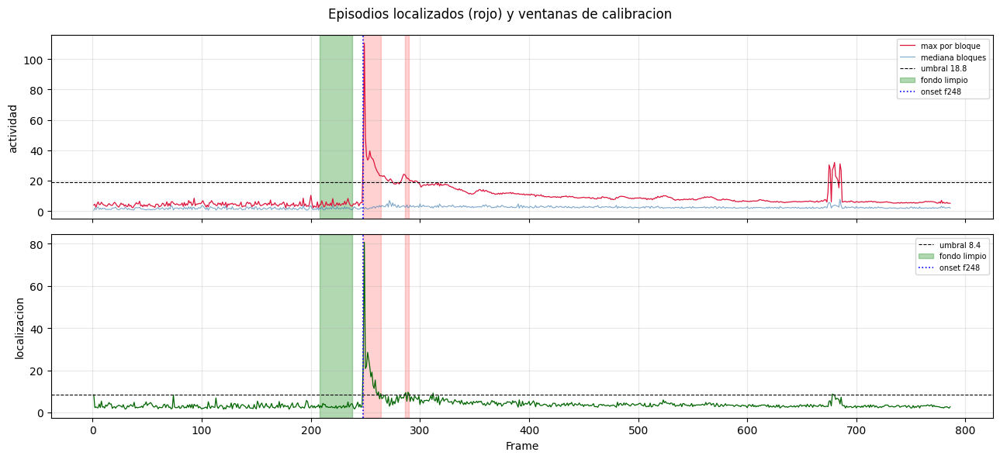

[onset] -> resultados\0_preprocesamiento\onset.json
[config] pivot_frame None -> 248 (escaneo de actividad; C1b lo afina a subframe)
[config] pivote f248 | análisis [248, 787)


In [3]:
# F0-1 — ESCANEO DE ACTIVIDAD  

ONSET_MANUAL    = None   
USAR_ONSET_AUTO = True   

SC  = F0.escaneo_actividad(CFG)
ONS = F0.detectar_onset(SC, FPS, manual=ONSET_MANUAL)
F0.grafico_actividad(SC, ONS, CFG.ruta(0, "escaneo_actividad.png"))

import json as _json
with open(CFG.art_onset, "w", encoding="utf-8") as _fh:
    _json.dump(ONS, _fh, indent=2, ensure_ascii=False)
print(f"[onset] -> {F0.ruta_corta(CFG.art_onset)}")

if CFG.pivot_frame is None:
    print(f"[config] pivot_frame None -> {ONS['frame_guess']} "
          f"(escaneo de actividad; C1b lo afina a subframe)")
    CFG.pivot_frame = ONS["frame_guess"]
    CFG.guardar_json()
elif USAR_ONSET_AUTO and ONS["frame_guess"] != CFG.pivot_frame:
    print(f"[config] pivot_frame {CFG.pivot_frame} -> {ONS['frame_guess']} "
          f"(escaneo de actividad)")
    CFG.pivot_frame = ONS["frame_guess"]
    CFG.guardar_json()
elif not USAR_ONSET_AUTO and ONS["frame_guess"] != CFG.pivot_frame:
    print(f"[config] el escaneo propone f{ONS['frame_guess']} pero se respeta "
          f"el pivot_frame manual f{CFG.pivot_frame} (USAR_ONSET_AUTO=False)")

FIN = CFG.analisis_fin or N_FRAMES
print(f"[config] pivote f{CFG.pivot_frame} | análisis [{CFG.pivot_frame}, {FIN})")


In [4]:
# F0-2 — METADATOS DEL VIDEO

import json
meta = dict(VID, escala=CFG.escala, pivot_frame=CFG.pivot_frame,
            analisis_fin=FIN, ancho_trabajo=W_WORK, alto_trabajo=H_WORK,
            gsd_m_px=CFG.gsd_m_px)
with open(CFG.art_video_meta, "w", encoding="utf-8") as fh:
    json.dump(meta, fh, indent=2)
print(json.dumps(meta, indent=2))

{
  "fps": 29.97002997002997,
  "n_frames": 787,
  "ancho": 3840,
  "alto": 2160,
  "escala": 0.5,
  "pivot_frame": 248,
  "analisis_fin": 787,
  "ancho_trabajo": 1920,
  "alto_trabajo": 1080,
  "gsd_m_px": null
}


[pivote] pivote_manual_20250815165143.pkl ya existe: no se vuelve a clicar (FORZAR_PIVOTE=True para rehacerlo).

  resolviendo el evento desde DJI_20250815165143_0003_V.MP4
    ts_inicio_video = 2025-08-15T16:51:43
    camara: lat -22.300393  lon -68.903535  alt 2963.6 m
            yaw -151.7  gimbal -59.7  focal 2700 px
    pivot_frame = 248   (fijado a mano)
  config.json actualizado
pivote : (1879, 1042) px 4K
gsd : 0.08765 m/px
config.json -> pivote_manual_20250815165143.pkl


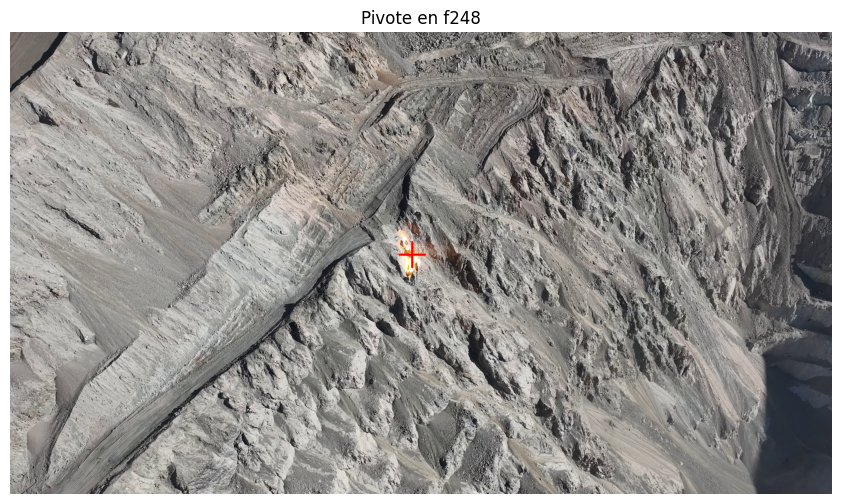

In [5]:
# F0-3 — PIVOTE DE LA TRONADURA

VALIDAR = False
 
if VALIDAR:
    #   PRIMER frame que anotes = el CENTRO (el pivote). Un solo clic.
    #   Los DEMAS               = el FRENTE. Varios clics sobre el arco.
    #   Minimo 3 frames distintos. Cuantos mas puntos, mejor el R2.
    #
    #   a/d ±1 frame   w/s ±10   +/- umbral   m vista   t estela   r rapido
    #   1 vecinos  2 cronicos  3 persistencia  4 arco    [ ] minv   ; ' Karco
    #   f 1:1 (clic derecho centra el 1:1)     z deshacer     Enter o q terminar
    FORZAR_CALIBRACION = False
    PAR_AB = dict(temp_aire_c=15.0)  

    if not str(CFG.calibracion_nombre).startswith("calibracion_airblast"):
        print(f"[calibracion] calibracion_nombre = {CFG.calibracion_nombre} "
              f"-> 'auto' (no es una calibracion acustica)")
        CFG.calibracion_nombre = "auto"

    CAL = F0.calibrar_airblast(CFG, ONS, par=PAR_AB, forzar=FORZAR_CALIBRACION)
    F0.grafico_airblast(CAL, CFG.ruta(0, "ajuste_airblast.png"))

    PIVOTE_NAT = (float(CAL["PIVOT_X_NAT"]), float(CAL["PIVOT_Y_NAT"]))
    GSD_C3     = 1.0 / float(CAL["PPM_NAT"])
    FUENTE_C3  = "airblast (acustica, independiente del DEM)"

else:
    import pickle

    FORZAR_PIVOTE = False  
    LADO_VIS      = 1500    

    _sello  = F0.sello_video(CFG.video_nombre) or "sinsello"
    RUTA_PIV = CFG.ruta(0, f"pivote_manual_{_sello}.pkl")

    def elegir_pivote(ruta_video, frame_ini, n_frames, lado_vis=1500):

        st = {"f": int(frame_ini), "piv": None, "zoom": False, "cen": None}
        vis = {"s": 1.0, "ox": 0, "oy": 0}       

        def _a_nat(xv, yv):
            return (xv / vis["s"] + vis["ox"], yv / vis["s"] + vis["oy"])

        def _cb(ev, x, y, flags, _p):
            if ev == cv2.EVENT_LBUTTONDOWN:
                st["piv"] = _a_nat(x, y)
            elif ev == cv2.EVENT_RBUTTONDOWN:
                st["cen"] = _a_nat(x, y)
                st["zoom"] = True

        VENT = "pivote"
        cv2.namedWindow(VENT, cv2.WINDOW_AUTOSIZE)
        cv2.setMouseCallback(VENT, _cb)

        with F0.LectorVideo(ruta_video, 1.0) as lec:    
            H_NAT, W_NAT = lec.forma_trabajo()              
            alto_vis = int(round(lado_vis * H_NAT / W_NAT))
            cache = {}
            while True:
                fi = int(np.clip(st["f"], 0, n_frames - 1))
                st["f"] = fi
                if fi not in cache:
                    fr = lec[fi]
                    if fr is None:
                        st["f"] = fi - 1
                        continue
                    cache[fi] = fr                        
                    if len(cache) > 24:
                        cache.pop(next(iter(cache)))
                base = cache[fi]

                if st["zoom"]:
                    cx, cy = st["cen"] or (W_NAT / 2, H_NAT / 2)
                    ox = int(np.clip(cx - lado_vis / 2, 0, max(0, W_NAT - lado_vis)))
                    oy = int(np.clip(cy - alto_vis / 2, 0, max(0, H_NAT - alto_vis)))
                    lienzo = base[oy:oy + alto_vis, ox:ox + lado_vis].copy()
                    vis.update(s=1.0, ox=ox, oy=oy)
                    modo = "1:1 (nativo)"
                else:
                    lienzo = cv2.resize(base, (lado_vis, alto_vis))
                    vis.update(s=lado_vis / W_NAT, ox=0, oy=0)
                    modo = f"ajuste x{vis['s']:.2f}"

                if st["piv"] is not None:
                    xv = int(round((st["piv"][0] - vis["ox"]) * vis["s"]))
                    yv = int(round((st["piv"][1] - vis["oy"]) * vis["s"]))
                    if 0 <= xv < lienzo.shape[1] and 0 <= yv < lienzo.shape[0]:
                        cv2.drawMarker(lienzo, (xv, yv), (0, 0, 255),
                                       cv2.MARKER_CROSS, 44, 2)
                        cv2.circle(lienzo, (xv, yv), 14, (0, 255, 255), 1)

                txt = [f"f{fi} / {n_frames - 1}   [{modo}]",
                       "clic = pivote | a/d +-1 | w/s +-10 | f 1:1 | "
                       "clic der. centra | z deshacer | Enter/q ok | ESC cancela"]
                if st["piv"] is not None:
                    txt.append(f"pivote nativo: ({st['piv'][0]:.0f}, {st['piv'][1]:.0f})")
                _pad, _dy = 10, 26
                _alto = min(lienzo.shape[0], _pad * 2 + _dy * len(txt))
                lienzo[0:_alto] = (lienzo[0:_alto] * 0.35).astype(np.uint8)
                for k, s_ in enumerate(txt):
                    cv2.putText(lienzo, s_, (12, _pad + _dy * (k + 1) - 8),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.62, (255, 255, 255), 1,
                                cv2.LINE_AA)

                cv2.imshow(VENT, lienzo)
                t = cv2.waitKey(20) & 0xFF
                if t in (13, ord("q")):
                    break
                elif t == 27:
                    st["piv"] = None
                    break
                elif t == ord("a"):
                    st["f"] -= 1
                elif t == ord("d"):
                    st["f"] += 1
                elif t == ord("w"):
                    st["f"] += 10
                elif t == ord("s"):
                    st["f"] -= 10
                elif t == ord("f"):
                    st["zoom"] = not st["zoom"]
                    st["cen"] = st["cen"] or st["piv"]
                elif t == ord("z"):
                    st["piv"] = None

        cv2.destroyWindow(VENT)
        for _ in range(4):           
            cv2.waitKey(1)
        return st["piv"]


    _prev = None
    if os.path.exists(RUTA_PIV) and not FORZAR_PIVOTE:
        with open(RUTA_PIV, "rb") as fh:
            _prev = pickle.load(fh)
        if _prev.get("VIDEO") != os.path.basename(CFG.video_nombre):
            print(f"[pivote] {os.path.basename(RUTA_PIV)} es de OTRO video: se ignora.")
            _prev = None

    if _prev is not None:
        PIVOTE_NAT = (float(_prev["PIVOT_X_NAT"]), float(_prev["PIVOT_Y_NAT"]))
        GSD_C3     = 1.0 / float(_prev["PPM_NAT"])
        print(f"[pivote] {os.path.basename(RUTA_PIV)} ya existe: no se vuelve a "
              f"clicar (FORZAR_PIVOTE=True para rehacerlo).")
    else:
        print(f"[pivote] clic al CENTRO de la tronadura. Arranco en el frame que "
              f"propuso el escaneo (f{CFG.pivot_frame}); con a/d y w/s puedes "
              f"moverte al que se vea mejor.\n")
        PIVOTE_NAT = elegir_pivote(CFG.video, CFG.pivot_frame, N_FRAMES,
                                   lado_vis=LADO_VIS)
        if PIVOTE_NAT is None:
            raise RuntimeError(
                "No se marco el pivote (se cancelo con ESC).")

        if not os.path.exists(CFG.dem):
            raise FileNotFoundError(
                f"Falta el DEM ({CFG.dem}) y sin el no se puede derivar la "
                f"escala de la metadata. Opciones: deja el DEM en datos/, o "
                f"corre esta celda con VALIDAR=True (el airblast mide la escala "
                f"sin DEM), o fija CFG.gsd_nativo_m_px a mano en F0-0.")

        _dem = F0.cargar_dem(CFG.dem)
        _cam = F0.CamaraGeo.desde_config(CFG, dem=_dem, escala=1.0,
                                         resolver_pivote=False, verbose=False)
        _pts = F0.raycast_pixeles(_cam, _dem, PIVOTE_NAT[0], PIVOTE_NAT[1])
        if not np.isfinite(_pts[0]).all():
            raise RuntimeError(
                "El rayo del pivote no corta el DEM. O el clic cayo en el cielo, "
                "o el DEM no cubre la zona, o la pose de la telemetria esta "
                "mal.")
        _rango = float(np.linalg.norm(_pts[0] - _cam.C))
        GSD_C3 = _rango / float(_cam.K[0, 0])

        print(f"\n[escala] pivote UTM   : E {_pts[0][0]:.2f}  N {_pts[0][1]:.2f}  "
              f"z {_pts[0][2]:.2f}")
        print(f"[escala] rango camara : {_rango:.2f} m   (focal {_cam.K[0,0]:.0f} px)")
        print(f"[escala] gsd nativo   : {GSD_C3:.5f} m/px  "
              f"-> {GSD_C3/CFG.escala:.5f} m/px de trabajo")

        _cal = dict(
            PIVOT_X_NAT=float(PIVOTE_NAT[0]), PIVOT_Y_NAT=float(PIVOTE_NAT[1]),
            PPM_NAT=1.0 / GSD_C3,
            VIDEO=os.path.basename(CFG.video_nombre),
            METODO="pivote manual (1 clic) + escala del modelo de camara",
            RANGO_M=_rango, FOCAL_PX_NAT=float(_cam.K[0, 0]),
            PIVOTE_UTM=[float(v) for v in _pts[0]],
            DEM=os.path.basename(CFG.dem_nombre),
            FRAME_CLIC=int(CFG.pivot_frame),
        )
        with open(RUTA_PIV, "wb") as fh:
            pickle.dump(_cal, fh)
        print(f"\n[pivote] -> {F0.ruta_corta(RUTA_PIV)}   (sellado para {_cal['VIDEO']})")
        del _dem, _cam, _pts

    CFG.calibracion_nombre = os.path.basename(RUTA_PIV)


print()
F0.refrescar_evento(CFG)
print(f"pivote : ({PIVOTE_NAT[0]:.0f}, {PIVOTE_NAT[1]:.0f}) px 4K")
print(f"gsd : {GSD_C3:.5f} m/px")
print(f"config.json -> {CFG.calibracion_nombre}")

with F0.LectorVideo(CFG.video, CFG.escala) as _lec:
    _fr = _lec[int(CFG.pivot_frame)]
_vis = _fr.copy()
_px = (int(PIVOTE_NAT[0] * CFG.escala), int(PIVOTE_NAT[1] * CFG.escala))
cv2.drawMarker(_vis, _px, (0, 0, 255), cv2.MARKER_CROSS, 60, 3)
plt.figure(figsize=(11, 6)); plt.imshow(_vis[:, :, ::-1])
plt.title(f"Pivote en f{CFG.pivot_frame}")
plt.axis("off"); plt.show()

In [6]:
# F0-4 — GEOMETRÍA DE LA ESCENA (pivote en píxeles + escala métrica)

GEO = F0.resolver_geometria(CFG, W_WORK, H_WORK)
F0.guardar_geometria(GEO, CFG.art_geometria)
CFG.gsd_nativo_m_px = GEO["gsd_nativo"]
CFG.guardar_json()

PIVOTE_PX_NAT = tuple(GEO["pivote_px_nat"])      # (x, y) en px NATIVOS (4K)
PIVOTE_PX     = tuple(GEO["pivote_px_trabajo"])  # (x, y) en px de TRABAJO
GSD_NAT       = GEO["gsd_nativo"]                # m/px en 4K
GSD_WORK      = GEO["gsd_trabajo"]               # m/px de trabajo
PPM_NAT       = 1.0 / GSD_NAT                    # px/m en 4K
T0_SUBFRAME   = GEO["t0_subframe"]               # timestamp del subframe
BLAST_FRAME   = GEO["blast_frame"]               # frame de la detonación

[geo] pivote  : nat (1879, 1042)  ->  trabajo (940, 521)   [PIVOT_X_NAT/PIVOT_Y_NAT (nativos por el sufijo de la clave)]
[geo] gsd     : 0.08765 m/px nativo  ->  0.17531 m/px trabajo   [PPM_NAT = 11.4086 px/m (nativos)]
[geo] cuadro  : 337 x 189 m   <- si esto no es plausible, la escala esta mal
[geo] disparo : t0=248.000 -> frame 248   (CFG.pivot_frame=248)
[geo] tranquila: [f208, f238)   [escaneo de actividad (onset.json)]
[geo] -> resultados\0_preprocesamiento\geometria.json


In [7]:
# F0-5 — MODELO DE FONDO (mediana pre-tronadura + ruido robusto MAD)

PREPROC   = F0.PREPROC_DEFECTO     
BG_WINDOW = F0.BG_WINDOW_DEFECTO   

preproc = F0.preprocesador(PREPROC)
bg_gray, bg_color, noise = F0.modelo_fondo(
    CFG.video, CFG.pivot_frame, escala=CFG.escala, preproc=preproc,
    dir_salida=CFG.dir_fase(0), bg_window=BG_WINDOW, step=1)

_ = F0.guardar_fondo(CFG.art_fondo, bg_gray, bg_color, noise,
                     meta=dict(preproc=PREPROC, bg_window=BG_WINDOW,
                               escala=CFG.escala, pivot=CFG.pivot_frame))

Fondo con frames [208, 248) paso 1 (escala 0.5, blur=(5, 5))...
Ruido robusto (MAD) promedio: 3.36 niveles
[fase0] fondo -> resultados\0_preprocesamiento\modelo_fondo.npz


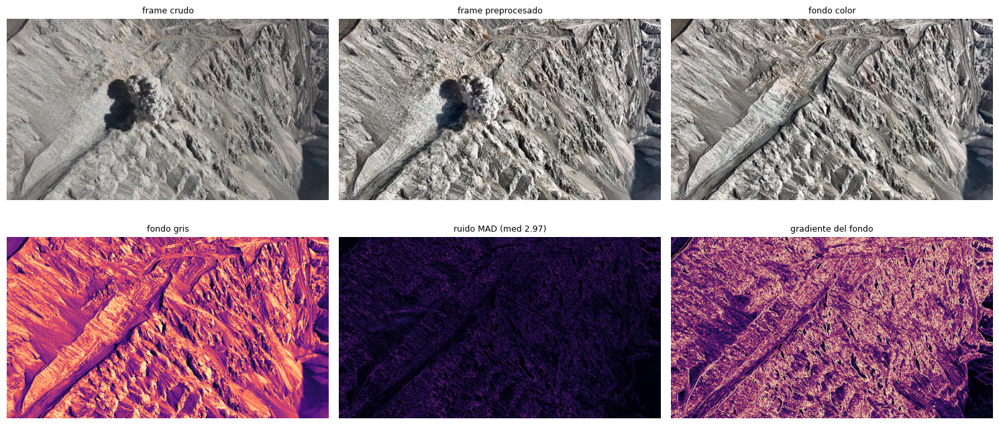

ruido: min 1.00  mediana 2.97  max 30.39 niveles


In [8]:
# F0-6 — Diagnóstico visual

with F0.LectorVideo(CFG.video, CFG.escala) as lec:
    crudo = lec[CFG.pivot_frame + 40]
prep = preproc(crudo)
grad = F0.magnitud_gradiente(bg_gray)

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, (im, t) in zip(ax.ravel(), [
        (crudo[:, :, ::-1], "frame crudo"),
        (prep[:, :, ::-1], "frame preprocesado"),
        (bg_color[:, :, ::-1], "fondo color"),
        (bg_gray, "fondo gris"),
        (noise, f"ruido MAD (med {np.median(noise):.2f})"),
        (grad, "gradiente del fondo")]):
    a.imshow(im, cmap=None if im.ndim == 3 else "magma")
    a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout()
plt.savefig(CFG.ruta(0, "qa_preprocesamiento.png"), dpi=120)
plt.show()

print(f"ruido: min {noise.min():.2f}  mediana {np.median(noise):.2f}  "
      f"max {noise.max():.2f} niveles")

## F0-7 — GEORREFERENCIA DEL FRAME  (necesita DEM)


  DEM EPSG:32719 | archivo (481, 561) | ventana (481, 561) | 12.5 m | z 2216-3373 m
  camara UTM : E 509936.1  N 7533919.9  z 2963.6
  mirada     : azimut 208.3 deg | depresion 59.7 deg
  u_img      -> azimut 298.3 deg
  v_img      -> azimut 28.3 deg
  escala en el plano del piso (m/px nativo): arriba 0.1134 | centro 0.0869 | abajo 0.0705  -> factor 1.61

  rango camara->pivote (modelo camara + DEM) :   236.7 m
  rango implicado por el airblast (PPM_NAT)  :   236.7 m
  discrepancia : +0.0 m  (+0.0 %)
  a modo de contraste, un desfase real de 102 m en el DEM daria -37 % / +37 %

    yaw  -131.7  r = 0.119
  yaw de metadatos  -151.7 deg
  yaw que maximiza la correlacion  -159.2 deg  (r = 0.241)
  diferencia -7.5 deg  ->  el mismo sesgo se traslada al azimut del viento

punto                    px_4K       UTM E        UTM N        z         lat         lon    dist
pivote               1879,1042   509881.32   7533810.59  2760.96  -22.301381  -68.904066     237
esq_sup_izq                1

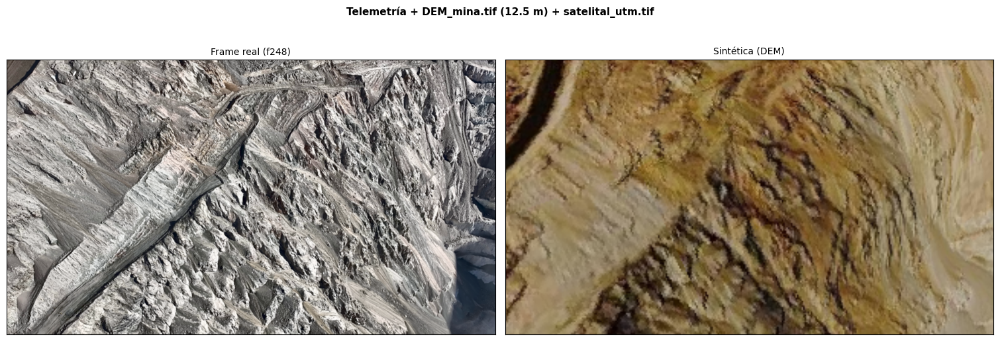

[fig] resultados\0_preprocesamiento\puntos_cardinales.png


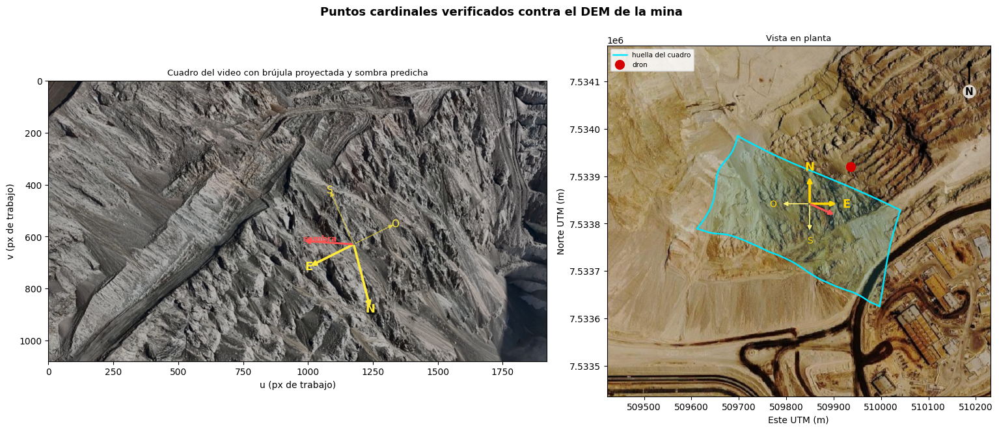

In [9]:
dem = F0.cargar_dem(CFG.dem)
cam = F0.CamaraGeo.desde_config(CFG, dem=dem)

print()
ESC = F0.verificar_escala(cam, GSD_NAT)

YAW_OPT = None
if os.path.exists(CFG.satelital):
    _bgg = cv2.cvtColor(cv2.imread(CFG.ruta(0, "bg_color.png")), cv2.COLOR_BGR2GRAY)
    print()
    YAWS, COR, YAW_OPT = F0.barrido_yaw(
        cam, dem, CFG.satelital, _bgg,
        CFG.frame_data["drone_yaw_deg"], CFG.frame_data["gimbal_pitch_deg"],
        delta=20.0, paso=2.5)
else:
    print(f"\n  (falta {F0.ruta_corta(CFG.satelital)}: sin barrido de yaw.")

print()
GEOREF = F0.georreferenciar_frame(CFG, cam, dem)
import json

GEOJSON = dict(
    video       = os.path.basename(CFG.video_nombre),
    dem         = os.path.basename(CFG.dem_nombre),
    crs         = str(dem["crs"]),
    escala      = CFG.escala,
    pivot_frame = int(CFG.pivot_frame),
    camara      = dict(C_utm    = [float(v) for v in cam.C],
                       R_c_w    = [[float(v) for v in fila] for fila in cam.R],
                       focal_px = float(cam.K[0, 0]),
                       ancho_px = int(cam.W), alto_px = int(cam.H)),
    pivote_utm  = [float(v) for v in cam.origen_utm],
    z_piso      = float(cam.z_piso),
    escala_airblast = ESC,
    yaw         = dict(metadatos_deg  = float(CFG.frame_data["drone_yaw_deg"]),
                       optimo_deg     = (float(YAW_OPT) if YAW_OPT is not None
                                         else None),
                       resolucion_deg = 10.0),
    sol         = cam.sol,
)
with open(CFG.art_georreferencia, "w", encoding="utf-8") as fh:
    json.dump(GEOJSON, fh, indent=2, ensure_ascii=False)
print(f"[georef] -> {F0.ruta_corta(CFG.art_georreferencia)}")

STEP = 6   
VS = F0.graficar_vista_sintetica(
    CFG, cam=cam, dem=dem, step=STEP,
    ruta_png=CFG.ruta(0, "vista_sintetica.png"))
plt.show()


_bg = cv2.imread(CFG.ruta(0, "bg_color.png"))
F0.graficar_puntos_cardinales(
    CFG, cam, dem, bg=_bg, XM=VS["X"], YM=VS["Y"],
    ruta_png=CFG.ruta(0, "puntos_cardinales.png"))
plt.show()


---

# FASE 1 — Deteccion y segmentacion de la columna de gas


| Salidas | Consumido por |
|---|---|
| `mascaras_gas.pkl` | Fases 2, 3 y 4 |
| `overlay_sam2.mp4` | verificación visual |

**Arquitectura — (`funciones_F1`)**

| Etapa | Método |
|---|---|
| Localización semántica | CLIPSeg contrastivo con **consenso multiescala** centrado en el pivote |
| Evidencia física | **novedad** contra el fondo crudo, con registro ECC y ajuste fotométrico |
| Segmentación | SAM 2 video, **opción B unificada**: reversa (nacimiento) + chunking sembrado por máscara propagada |

In [10]:
# F1-0 — ARRANQUE

CTX = F0.iniciar(run="")

CFG, VID              = CTX["CFG"], CTX["VID"]
FPS, N_FRAMES, FIN    = CTX["FPS"], CTX["N_FRAMES"], CTX["FIN"]
H_WORK, W_WORK, FORMA = CTX["H_WORK"], CTX["W_WORK"], CTX["FORMA"]
PIVOTE                = CFG.pivot_frame

[config] leida de resultados\config.json

raiz        : .
run         : (sin subcarpeta de version)
resultados  : resultados
video       : datos\DJI_20250815165143_0003_V.MP4
escala      : 0.5  |  pivote f248  |  GSD None m/px
video   : 3840x2160 | 29.97 fps | 787 frames
trabajo : 1920x1080 | analisis [248, 787)


## F1-1 — GEOMETRÍA Y FONDO CRUDO


In [11]:
PIVOTE_PX_MANUAL = None   
GSD_MANUAL       = None   

GEO, _ = F1.geometria_escena(CFG, W_WORK, H_WORK)
PX, PY = F1.resolver_pivote_px(CFG, W_WORK, H_WORK,
                               manual=PIVOTE_PX_MANUAL, geo=GEO)
GSD    = F1.resolver_gsd(CFG, W_WORK, manual=GSD_MANUAL, geo=GEO)

VENTANA_FONDO = GEO.get("ventana_tranquila") 
FONDO, RUIDO_BASE = F1.fondo_crudo(CFG.video, PIVOTE, escala=CFG.escala,
                                   rango=VENTANA_FONDO)


[geo] fuente: geometria.json
[geo] pivote 940, 521 px de trabajo | gsd 0.17531 m/px | cuadro 337 m de ancho
[pivote] (940, 521) px de trabajo   [PIVOT_X_NAT/PIVOT_Y_NAT (nativos por el sufijo de la clave)]
[gsd] 0.17531 m/px de trabajo  (PPM_NAT = 11.4086 px/m (nativos))
      ancho del cuadro = 337 m  <- si esto no es plausible, revisa la calibracion
[fondo crudo] 1080x1920 de [f208, f238) (30 frames, ventana tranquila de la calibracion) | ruido base = 3.00
              -> novedad_min = 18.0 | novedad_ancla = 75.0


## F1-2 — PARÁMETROS Y MOTOR DE DETECCIÓN


In [12]:
PRESET = "hibrido"

PAR_DET, PAR_SAM = F1.preset(PRESET)

PAR_DET.update(
    escalas_m=(None, 50.0, 30.0), consenso_min=2, lado_min_px=round(0.2083 * W_WORK),
    r_pivote_m=60.0, neg_anillo_m=(60.0, 200.0), pos_repartidos=True,
)
PAR_SAM.update(
    t_busqueda_ini=0.07, t_busqueda_fin=1.85, clip_fuerte=round(0.001929 * H_WORK * W_WORK), skip=2,
)
print(f"[preset] {PRESET}")
print(f"   det: {PAR_DET}")
print(f"   sam: {PAR_SAM}")

detector = F1.DetectorCLIPSeg(CFG.clipseg_id, dir_local=CFG.dir_clipseg)
DET = F1.Detector(detector, FORMA, (PX, PY), GSD, FONDO, RUIDO_BASE,
                    par=PAR_DET)

LEC = F0.LectorVideo(CFG.video, CFG.escala)
DET.chequeo_registro(LEC, [max(0, PIVOTE - 40), max(0, PIVOTE - 5)])

FIRMA = F0.hash_parametros(dict(motor="V8", preset=PRESET, det=DET.p,
                                sam=PAR_SAM, escala=CFG.escala, pivote=PIVOTE,
                                fin=FIN, px=round(PX, 1), py=round(PY, 1),
                                gsd=round(GSD, 6), ruido=round(RUIDO_BASE, 4),
                                modelo=CFG.clipseg_id))
CACHE_MASKS = f"sam2_{PRESET}_{FIRMA}"
DIR_FRAMES  = os.path.join(CFG.dir_cache, "sam2_frames")   
print(f"\nfirma: {FIRMA} -> {F0.ruta_corta(CACHE_MASKS)}")


[preset] hibrido
   det: {'ventana_max_m': 80.0, 'escalas_m': (None, 50.0, 30.0), 'consenso_min': 2, 'lado_min_px': 400, 'r_pivote_m': 60.0, 'neg_anillo_m': (60.0, 200.0), 'pos_repartidos': True}
   sam: {'ancla_modo': 'primero', 'siembra_mask': False, 'resync_frac': 0.0, 't_busqueda_ini': 0.07, 't_busqueda_fin': 1.85, 'clip_fuerte': 4000, 'skip': 2}


Loading weights:   0%|          | 0/462 [00:00<?, ?it/s]

CLIPSeg listo | nube: ['white dust cloud', 'dark gray smoke plume'] | fondo: ['bare rocky terrain', 'dirt road', 'mountain slope', 'dark shadow on the ground']
novedad px > 18.0 | ancla (mediana) > 75.0
pivote (940, 521) | r=60 m = 342 px | anillo negativo 342-1141 px
consenso multiescala: completo | +-50m (570px) | +-30m (342px) | piso 400 px
[chequeo] registro ECC: activo
[chequeo] f208: shift=(-0.1, +0.2) px -0.00deg | gain=0.957 | 0.0% sobre umbral
[chequeo] f243: shift=(+0.1, -0.1) px -0.00deg | gain=0.947 | 0.0% sobre umbral
   Objetivo: <10% en todos.

firma: 0cdfb680 -> sam2_hibrido_0cdfb680


## F1-3 — SEGMENTACIÓN SAM 2


In [13]:
SEMILLA_PROD = 0
np.random.seed(SEMILLA_PROD)
CACHE_MASKS = f"sam2_{PRESET}_{FIRMA}_s{SEMILLA_PROD}"
print(f"semilla de producción: {SEMILLA_PROD} -> {F0.ruta_corta(CACHE_MASKS)}")

semilla de producción: 0 -> sam2_hibrido_0cdfb680_s0


In [14]:
_cache = F0.cargar_cache(CACHE_MASKS, CFG.dir_cache)
if isinstance(_cache, dict) and "masks" in _cache and "info" in _cache:
    masks, info = _cache["masks"], _cache["info"]
    print(f"{len(masks)} máscaras desde caché (ancla f{info.get('ancla')}).")
elif _cache is not None:                     
    masks, info = _cache, {}
    print(f"{len(masks)} máscaras desde caché.")
else:
    seg = F1.Segmentador(CFG.sam2_ckpt, CFG.sam2_cfg, CFG.dispositivo)
    masks, info = seg.segmentar(
        CFG.video, DET, FORMA, DIR_FRAMES,
        pivot_frame=PIVOTE, analisis_fin=FIN, fps=FPS, escala=CFG.escala,
        par=PAR_SAM)
    F0.guardar_cache(dict(masks=masks, info=info), CACHE_MASKS, CFG.dir_cache)
    print("\n-- Siembra por bloque --")
    for cid, f0_, tipo, motivo in info["log_siembra"]:
        print(f"  bloque {cid:>2} @ f{f0_:>4} : {tipo:<22} | {motivo}")


[cache] cargado: sam2_hibrido_0cdfb680_s0.pkl
270 máscaras desde caché (ancla f250).


## F1-4 — SALIDA + VIDEO DE VERIFICACIÓN


In [15]:
SKIP = PAR_SAM.get("skip", F1.PAR_SAM2["skip"])

F0.guardar_mascaras(masks, CFG.art_mascaras_gas, meta=dict(
    metodo="SAM2",
    firma=FIRMA, skip=SKIP, escala=CFG.escala, forma=FORMA, pivot=PIVOTE,
    gsd_trabajo=GSD, pivote_px=(PX, PY), ruido_base=RUIDO_BASE, **info))

_ = F1.video_overlay(CFG.video, masks, CFG.ruta(1, "overlay_sam2.mp4"),
                 fps=FPS / max(1, SKIP), escala=CFG.escala)

[mascaras] 270 frames -> resultados\1_deteccion_gas\mascaras_gas.pkl (559.9 MB)
[video] resultados\1_deteccion_gas\overlay_sam2.mp4


## F1-5 — Máscaras de sombra (detector multicanal)

El detector viene de **Arjomandi et al. (2022)**: en vez de decidir «sombra vs
gas» con un umbral en grises, suma evidencia de cuatro canales.

| Señal | Cómo separa |
|---|---|
| **L\*** (LAB) | la sombra es oscura → L\* bajo |
| **S** (HSV) | el gas es grisáceo y pierde saturación; la sombra conserva el color del suelo |
| **Cr** (YCrCb) | el gas de tronadura tira a cálido → Cr alto |
| **\|∇\|** | la sombra **conserva** la textura del suelo, el gas la destruye |


In [16]:
PRE_SOMBRA = 40      
SKIP_SOMBRA = 1      

FONDO_COLOR = F1.fondo_crudo_color(CFG.video, PIVOTE, escala=CFG.escala,
                                   rango=GEO.get("ventana_tranquila"))

masks_som, meta_som = F1.detectar_sombras(
    CFG.video, FONDO_COLOR, pivot_frame=PIVOTE, fin=(FIN or N_FRAMES), escala=CFG.escala,
    pre=PRE_SOMBRA, skip=SKIP_SOMBRA,
    umbral=F1.UMBRAL_SOMBRA_V6, area_min=F1.AREA_MIN_SOMBRA_V6)

F0.guardar_mascaras(masks_som, CFG.art_mascaras_sombra, meta=meta_som,
                    empaquetar_bits=True)

F0.sellar(CFG, 1, dict(mascaras=int(len(masks)), skip=int(SKIP),
                       firma=str(FIRMA), pivot_frame=int(CFG.pivot_frame),
                       sombras=int(len(masks_som)),
                       sombras_pre=int(meta_som["n_pre"])))

[fondo crudo color] 1080x1920 de [f208, f238) (ventana tranquila de la calibracion)
[sombra multicanal] f208 .. f787  (pre=40, skip=1, umbral=0.55, area_min=800)
  579 mascaras | cobertura media 7.72% (min 4.93%, max 10.71%)
  frames pre-tronadura: 40  (ok, la sombra estatica se puede construir)
[mascaras] 579 frames -> resultados\1_deteccion_gas\mascaras_sombra.pkl (150.1 MB, empaquetadas a bits)


{'video': 'DJI_20250815165143_0003_V.MP4',
 'fases': {'0': {'video': 'DJI_20250815165143_0003_V.MP4',
   'procedencia': {'video': 'DJI_20250815165143_0003_V.MP4',
    'video_bytes': 434589456,
    'ts_inicio_video': 'nombre del archivo',
    'frame_data': 'telemetria djmd del MP4',
    'calibracion': 'fijada a mano: pivote_manual_20250815165143.pkl',
    'calibracion_esquema': 'v7.2',
    'pivot_frame': 'PENDIENTE: lo pone C0b (onset) o C1b (calibracion)',
    'insumos_externos': {'dem': 'DEM_mina.tif',
     'ortofoto': 'satelital_utm.tif',
     'bounds_mina': [506500.0, 7532500.0, 513500.0, 7538500.0]},
    'deriva_dron': {'este_m': 0.195,
     'norte_m': 0.155,
     'vertical_m': 0.599,
     'yaw_deg': 0.8,
     'gimbal_deg': 0.0,
     'horizontal_m': 0.249,
     'fps': 29.97}}},
  '1': {'video': 'DJI_20250815165143_0003_V.MP4',
   'mascaras': 270,
   'skip': 2,
   'firma': '0cdfb680',
   'pivot_frame': 248,
   'sombras': 579,
   'sombras_pre': 40},
  '2': {'video': 'DJI_202508151651

## F1-6 — COMPROBACIÓN: CLIPSeg vs máscara SAM 2 

frames: [257, 293, 368, 488, 698]


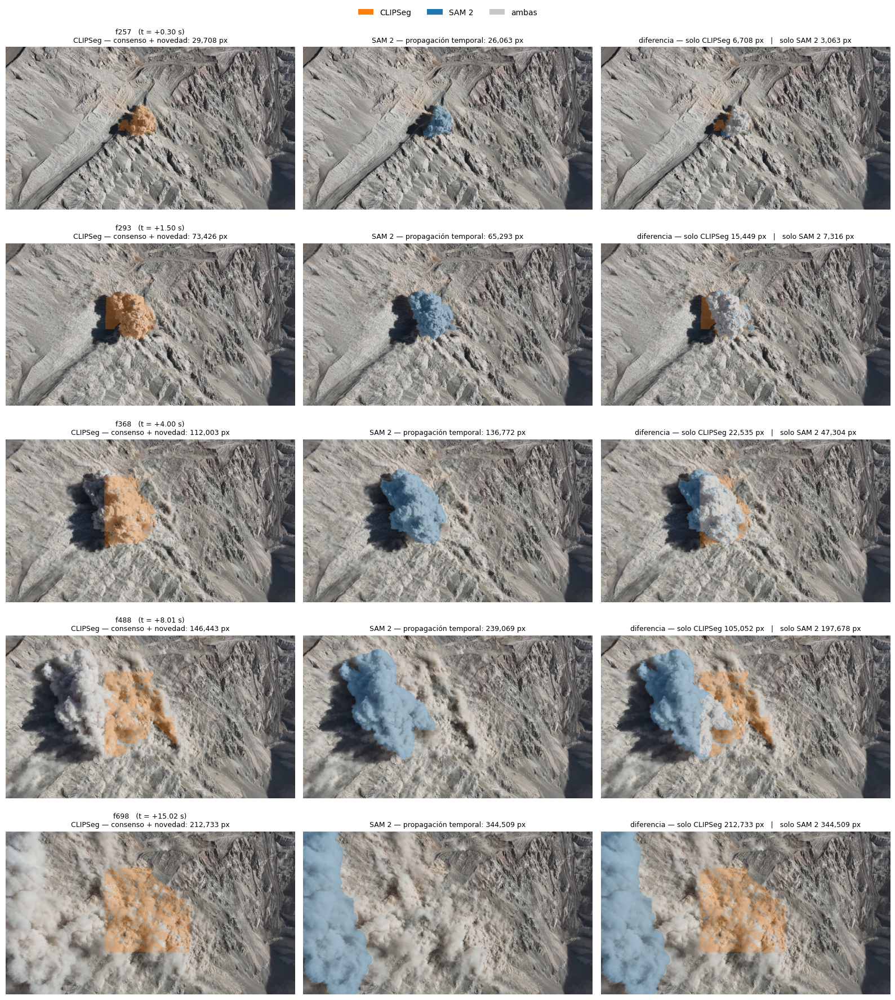

In [17]:
T_VER = (0.3, 1.5, 4.0, 8.0, 15.0)
FRAMES_VER = [PIVOTE + round(t * FPS) for t in T_VER]
FRAMES_VER = [f for f in FRAMES_VER if min(masks) - SKIP <= f <= max(masks)]
print("frames:", FRAMES_VER)

F1.comparar_mascaras(FRAMES_VER, DET, LEC, masks, tol=max(2, SKIP),
                     fps=FPS, pivot_frame=PIVOTE)

LEC.close()


## F1-7 — Métrica interna de SAM 2

Carga una segunda copia de SAM 2 en modo
imagen y re-puntúa 40 frames, que en CPU son varios minutos.

[calidad SAM2] 40 frames de 270 (f249 .. f786) en cpu
   10/40  (0.8 min)
   20/40  (1.6 min)
   30/40  (2.3 min)
   40/40  (3.1 min)

  iou_predicho  mediana 0.855  | p10 0.629
  estabilidad   mediana 0.818  | p10 0.635
  iou_vs_video  mediana 0.940   <- acuerdo imagen/video del MISMO modelo
  frames con >1 componente: 1 (2%)
[csv] 40 filas -> resultados\1_deteccion_gas\diagnosticos\SAM 2 interno\calidad_sam2.csv
[figura] resultados\1_deteccion_gas\diagnosticos\SAM 2 interno\confianza_sam2.png


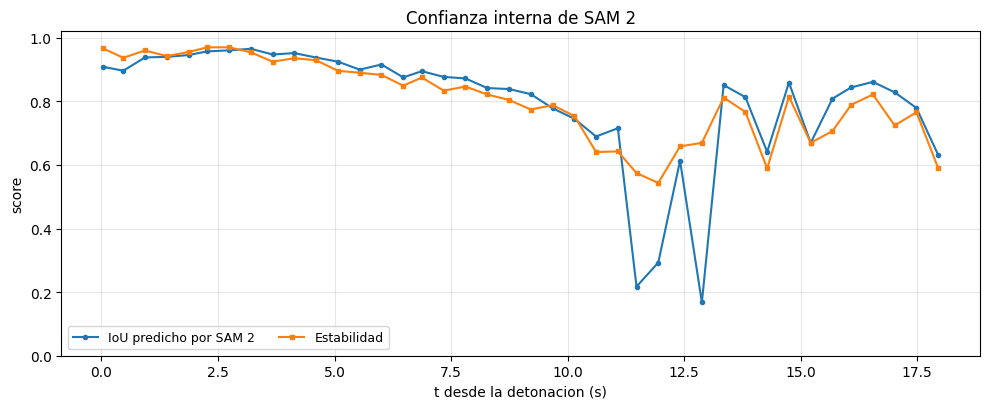

[figura] resultados\1_deteccion_gas\diagnosticos\SAM 2 interno\acuerdo_sam2.png


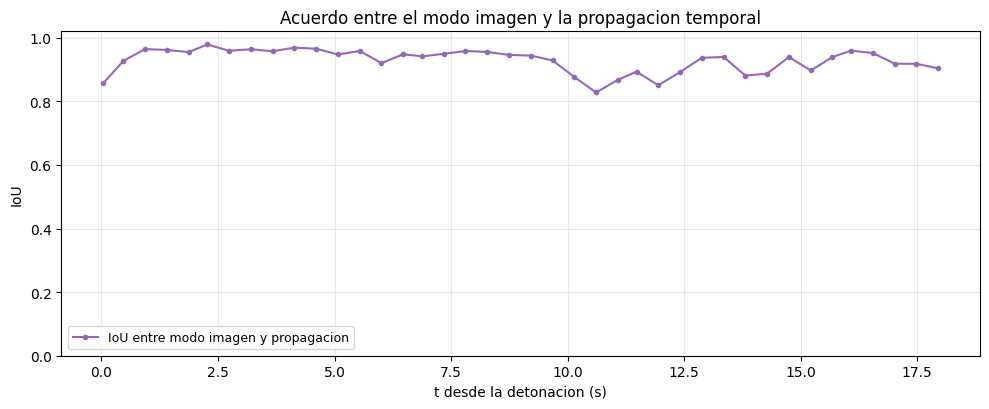

In [18]:
CORRER_SAM2_INTERNO = True  # <-- True para correr la métrica interna de SAM 2 

N_MUESTRAS     = 40      
FRAMES_CALIDAD = None    
SUB_INT        = F1.dir_experimento(CFG, "interno")

if not CORRER_SAM2_INTERNO:
    print("[F1-7] CORRER_SAM2_INTERNO=False -> se omite la métrica interna.")
    SOSPECHOSOS = []
else:
    filas_q, cols_q, res_q = F1.calidad_sam2(
        masks, CFG.video, CFG.sam2_ckpt, CFG.sam2_cfg, CFG.dispositivo,
        escala=CFG.escala, fps=FPS, pivot_frame=CFG.pivot_frame,
        frames=FRAMES_CALIDAD, n_muestras=N_MUESTRAS)

    F0.guardar_csv(filas_q, cols_q,
                   CFG.ruta(1, "diagnosticos", SUB_INT, "calidad_sam2.csv"))

    _c   = {n: i for i, n in enumerate(cols_q)}
    _t   = np.array([f[_c["t_s"]] for f in filas_q], float)
    _iou = np.array([f[_c["iou_predicho"]] for f in filas_q], float)
    _est = np.array([f[_c["estabilidad"]] for f in filas_q], float)
    _agr = np.array([f[_c["iou_vs_video"]] for f in filas_q], float)
    _val = np.isfinite(_est)
    _p20 = float(np.percentile(_est[_val], 20)) if _val.any() else 0.0

    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.plot(_t, _iou, "-o", ms=3, label="IoU predicho por SAM 2")
    ax.plot(_t, _est, "-s", ms=3, label="Estabilidad")
    ax.set_ylabel("score"); ax.set_ylim(0, 1.02)
    ax.set_xlabel("t desde la detonacion (s)")
    ax.legend(fontsize=9, ncol=2, loc="lower left"); ax.grid(alpha=.3)
    ax.set_title("Confianza interna de SAM 2")
    fig.tight_layout()
    _png1 = CFG.ruta(1, "diagnosticos", SUB_INT, "confianza_sam2.png")
    fig.savefig(_png1, dpi=130, bbox_inches="tight")
    print(f"[figura] {F0.ruta_corta(_png1)}")
    display(fig); plt.close(fig)

    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.plot(_t, _agr, "-o", ms=3, color="tab:purple",
            label="IoU entre modo imagen y propagacion")
    ax.set_ylabel("IoU"); ax.set_ylim(0, 1.02)
    ax.set_xlabel("t desde la detonacion (s)")
    ax.legend(fontsize=9, loc="lower left"); ax.grid(alpha=.3)
    ax.set_title("Acuerdo entre el modo imagen y la propagacion temporal")
    fig.tight_layout()
    _png2 = CFG.ruta(1, "diagnosticos", SUB_INT, "acuerdo_sam2.png")
    fig.savefig(_png2, dpi=130, bbox_inches="tight")
    print(f"[figura] {F0.ruta_corta(_png2)}")
    display(fig); plt.close(fig)

## F1-8 — Validación de consistencia 

In [19]:
CORRER_CONSISTENCIA = False   # <-- True re-corre el estudio completo (~40 min por variante)
BORRAR_FALLIDAS     = True    

VARIANTES = [
    "identidad",                                     # control
    "full",                                          # resolución
    "rot90", "rot180", "espejo_h",                   # geometría
    "brillo_mas", "brillo_menos", "gamma_alta",      # fotometría
    "saturacion_baja", "balance_calido",
    "ruido5", "jpeg40",                              # sensor / códec
]

SEMILLA          = 0
GUARDAR_MASCARAS = True   
VELOCIDAD        = 0.5  

FIRMA_CONS = f"{PRESET}_{FIRMA}"

if not CORRER_CONSISTENCIA:
    print("[F1-8] CORRER_CONSISTENCIA=False -> se omite el estudio.")
    F1.inventario_mascaras(CFG, FIRMA_CONS, VARIANTES, FORMA, masks_ref=masks)
else:
    if BORRAR_FALLIDAS:
        _fallidas = []
        for _n in VARIANTES:
            _o = F0.cargar_cache(F1.clave_cache_variante(FIRMA_CONS, _n),
                                 CFG.dir_cache, verbose=False)
            if _o is not None and _o.get("meta", {}).get("estado") == "error":
                _fallidas.append(_n)
        if _fallidas:
            print(f"[cache] {len(_fallidas)} variante(s) con error guardado: "
                  f"{_fallidas}")
            F1.borrar_cache_variantes(CFG, FIRMA_CONS, _fallidas)

    seg_val = F1.Segmentador(CFG.sam2_ckpt, CFG.sam2_cfg, CFG.dispositivo)

    filas, resumen, consenso = F1.estudio_consistencia(
        CFG, masks_ref=masks, detector=detector, seg=seg_val, geo=GEO,
        par_det=PAR_DET, par_sam=PAR_SAM, fps=FPS, fin=FIN,
        pivote=CFG.pivot_frame,
        gsd_ref=GSD, pivote_ref_px=(PX, PY), forma_ref=FORMA,
        dir_frames=DIR_FRAMES, variantes=F1.catalogo_variantes(VARIANTES),
        firma=FIRMA_CONS, n_consenso=40, semilla=SEMILLA,
        guardar_mascaras=GUARDAR_MASCARAS)

    F1.tabla_consistencia(resumen)


    F1.guardar_diagnosticos_consistencia(
        CFG, "consistencia", filas, resumen, consenso, FORMA)

    F1.inventario_mascaras(CFG, FIRMA_CONS, VARIANTES, FORMA, masks_ref=masks)
    F1.videos_diagnostico(CFG, FIRMA_CONS, "consistencia", VARIANTES, FORMA,
                          fps_fuente=FPS, masks_ref=masks, velocidad=VELOCIDAD,
                          par=None)

[F1-8] CORRER_CONSISTENCIA=False -> se omite el estudio.
variante              frames  fuente
------------------------------------------------
identidad                270  completa
full                     270  completa
rot90                    270  completa
rot180                   270  completa
espejo_h                 270  completa
brillo_mas               270  completa
brillo_menos             270  completa
gamma_alta               270  completa
saturacion_baja          270  completa
balance_calido           270  completa
ruido5                   270  completa
jpeg40                     0  ausente

  SIN CACHE: ['jpeg40']


## F1-8 bis — Re-referencia del estudio de consistencia

Recalcula las métricas de `consistencia.csv`, `consistencia_resumen.csv` y `consistencia_control.csv` contra las máscaras de producción actuales (semilla fija), sin volver a segmentar las variantes. Las variantes de F1-8 se comparan desde sus máscaras en caché; las semillas de control de F1-8c solo guardan el área, por lo que en ellas se recalcula la razón de área y IoU, Dice y centroide quedan vacíos.

[csv] 12 filas -> resultados\1_deteccion_gas\diagnosticos\Consistencia\consistencia_resumen.csv
[csv] 2970 filas -> resultados\1_deteccion_gas\diagnosticos\Consistencia\consistencia.csv
[consenso] 11 variantes, 40 frames, voto >= 6
  CV del conteo de pixeles : mediana 1.161 | p90 2.098
  IoU medio vs consenso    : mediana 0.876 | min 0.810
[csv] 40 filas -> resultados\1_deteccion_gas\diagnosticos\Consistencia\consistencia_consenso.csv
[figura] resultados\1_deteccion_gas\diagnosticos\Consistencia\conteo_pixeles.png


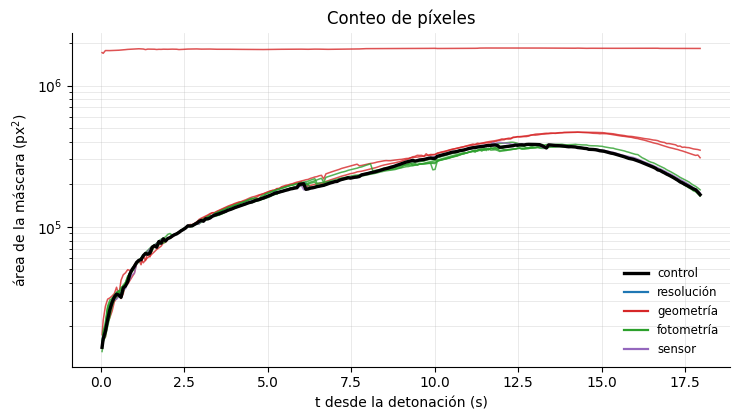

[figura] resultados\1_deteccion_gas\diagnosticos\Consistencia\ranking_robustez.png


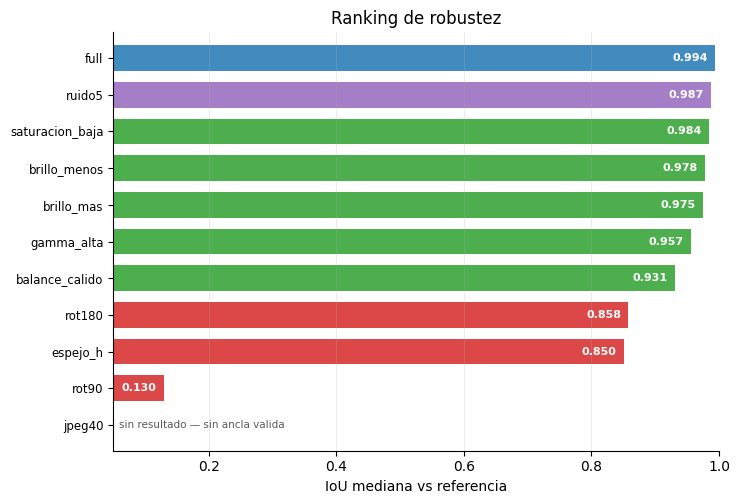

[figura] resultados\1_deteccion_gas\diagnosticos\Consistencia\razon_area.png


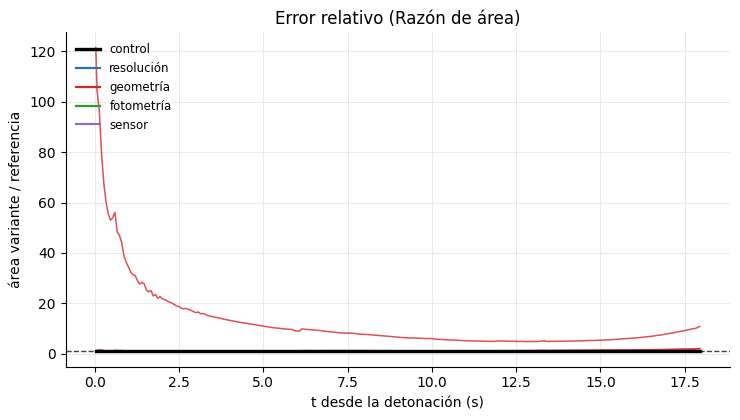


variante              IoU med  IoU p10  area v/r       p10-p90  dcent px  ancla    min
--------------------------------------------------------------------------------------
identidad               1.000    1.000     1.000   1.00-1.00         0.0    250   34.3  <- control
full                    0.994    0.966     1.004   1.00-1.03         0.8    250  131.3
ruido5                  0.987    0.960     1.003   0.99-1.03         1.5    250   94.4
saturacion_baja         0.984    0.948     1.000   0.98-1.04         2.2    250   34.0
brillo_menos            0.978    0.921     0.992   0.93-1.01         3.2    250   35.8
brillo_mas              0.975    0.927     1.004   0.94-1.05         5.0    250   36.6
gamma_alta              0.957    0.924     1.000   0.94-1.05         9.8    250   34.6
balance_calido          0.931    0.880     1.009   0.94-1.12        13.1    250   34.1
rot180                  0.858    0.678     1.069   1.01-1.45        41.1    250   38.1
espejo_h                0.850 

In [20]:
import csv

REREFERENCIAR = True

if REREFERENCIAR:
    _SUB  = F1.dir_experimento(CFG, "consistencia")
    _ruta = lambda n: CFG.ruta(1, "diagnosticos", _SUB, n)

    def _fila(nombre, f, mv=None, av=None):
        mr = F1._bin(masks[f])
        ar = int(mr.sum())
        if mv is not None:
            av = int(mv.sum())
            (cx, cy), (cxr, cyr) = F1._centroide(mv), F1._centroide(mr)
            d = float(np.hypot(cx - cxr, cy - cyr)) if av and ar else np.nan
            m = [round(F1.iou_mascaras(mv, mr), 4), round(F1.dice_mascaras(mv, mr), 4),
                 round(d, 2), round(d * GSD, 2) if not np.isnan(d) else np.nan]
        else:
            m = [np.nan] * 4
        return [nombre, f, round((f - CFG.pivot_frame) / FPS, 3), ar, av,
                round(av / ar, 4) if ar else np.nan] + m

    filas_r, resumen_r, consenso_r = [], [], {}
    for var in F1.catalogo_variantes(VARIANTES):
        n   = var["nombre"]
        obj = F0.cargar_cache(F1.clave_cache_variante(FIRMA_CONS, n), CFG.dir_cache, verbose=False)
        if obj is None:
            print(f"  {n}: sin caché, se omite")
            continue
        bits, fuente = F1._bits_variante(CFG, FIRMA_CONS, n, FORMA)
        f_v = []
        if fuente == "completa":
            f_v = [_fila(n, f, mv=F0.desempaquetar(bits[f], FORMA) > 0)
                   for f in sorted(set(bits) & set(masks))]
        elif obj["meta"].get("estado") != "error":
            print(f"  {n}: sin máscaras completas ({fuente}), no se puede re-referenciar")
        filas_r += f_v
        if obj.get("sub"):
            consenso_r[n] = obj["sub"]
        resumen_r.append(F1._resumir_variante(n, var, f_v, obj["meta"]))

    F1.guardar_diagnosticos_consistencia(CFG, "consistencia", filas_r, resumen_r, consenso_r, FORMA)
    F1.tabla_consistencia(resumen_r)

    _csv_ctrl = _ruta("consistencia_control.csv")
    if os.path.exists(_csv_ctrl):
        with open(_csv_ctrl, encoding="utf-8") as fh:
            _ctrl = [_fila(r["variante"], int(r["frame"]), av=int(float(r["area_var"])))
                     for r in csv.DictReader(fh) if int(r["frame"]) in masks]
        F0.guardar_csv(_ctrl, F1.COLUMNAS_CONSISTENCIA, _csv_ctrl)
        print(f"[F1-8 bis] {len(_ctrl)} filas de control re-referenciadas")

## F1-8b — Visualización de las variantes

[figura] resultados\1_deteccion_gas\diagnosticos\Consistencia\razon_area_sin_geometria.png


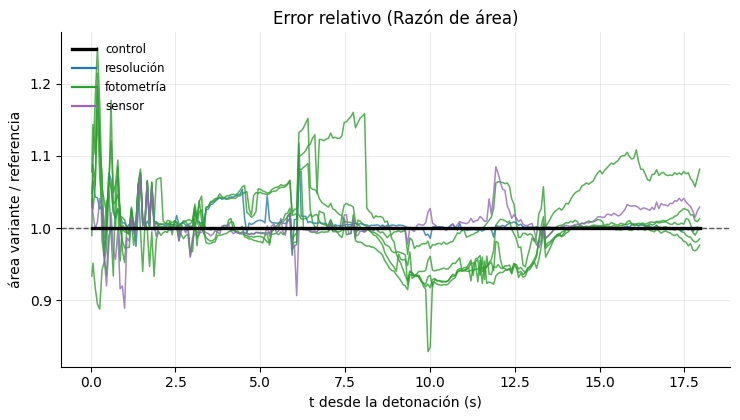

In [21]:
import csv

_SUB = F1.dir_experimento(CFG, "consistencia")
with open(CFG.ruta(1, "diagnosticos", _SUB, "consistencia.csv"), encoding="utf-8") as fh:
    _filas = [[r["variante"], int(r["frame"]), float(r["t_s"]), float(r["area_ref"]),
               float(r["area_var"]), float(r["razon_area"])]
              for r in csv.DictReader(fh)]

_filas_sin_geo = [r for r in _filas if F1.familia(r[0]) != "geometría"]
F1.grafico_razon_area(_filas_sin_geo,
                      ruta=CFG.ruta(1, "diagnosticos", _SUB, "razon_area_sin_geometria.png"))

[grilla] resultados\1_deteccion_gas\diagnosticos\Consistencia\grilla_variantes.png


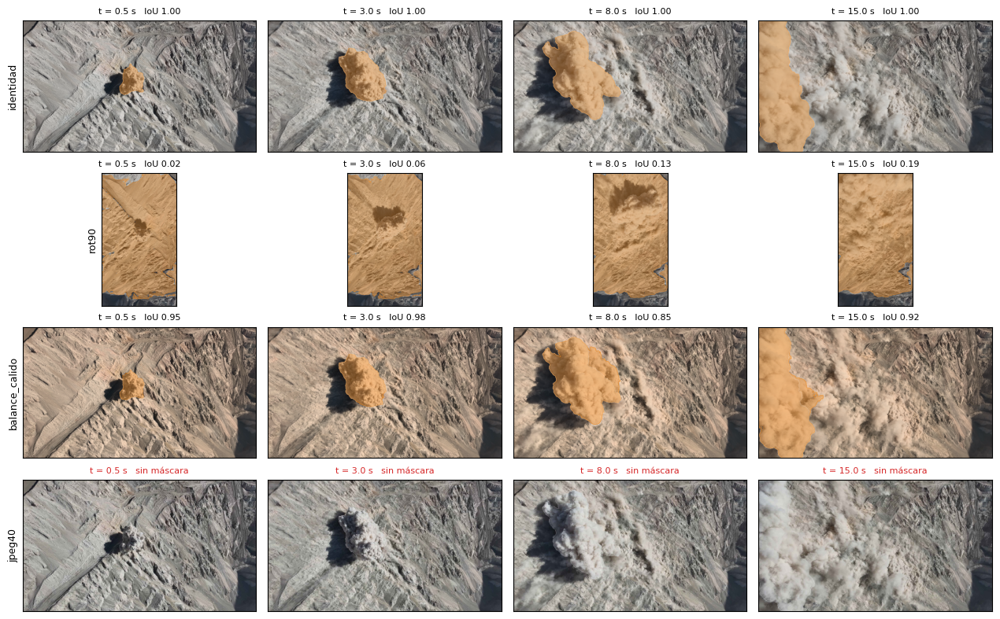

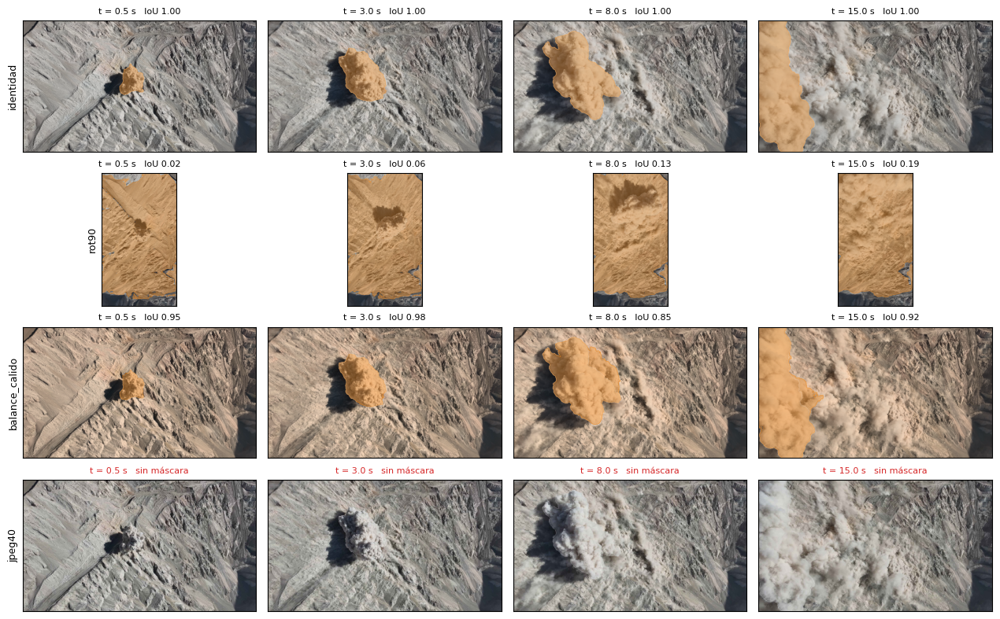

In [22]:
GENERAR_VIDEOS = False
GRILLA         = ["identidad", "rot90", "balance_calido", "jpeg40"]
TIEMPOS_GRILLA = [0.5, 3.0, 8.0, 15.0]


if GENERAR_VIDEOS:
    F1.videos_variantes(CFG, FIRMA_CONS, VARIANTES, FORMA, fps_fuente=FPS,
                        masks_ref=masks, velocidad=VELOCIDAD)

_SUB = F1.dir_experimento(CFG, "consistencia")
F1.grilla_variantes(CFG, FIRMA_CONS, GRILLA, FORMA, TIEMPOS_GRILLA,
                    fps_fuente=FPS, masks_ref=masks,
                    ruta=CFG.ruta(1, "diagnosticos", _SUB, "grilla_variantes.png"))

## F1-8c — Banda de control (semillas)

Repite el control `identidad` con otras semillas de siembra. La envolvente mín–máx de la razón de área entre todas las corridas del control (la de F1-8 con `SEMILLA` más estas) es el piso de ruido de la Fig. 10. La franja gris marca el tramo de caída de la confianza interna de SAM 2 (F1-7).

`CORRER_BANDA = True` corre las semillas que falten (~35 min cada una); las ya corridas se leen desde caché.

[figura] resultados\1_deteccion_gas\diagnosticos\Consistencia\razon_area_banda.png


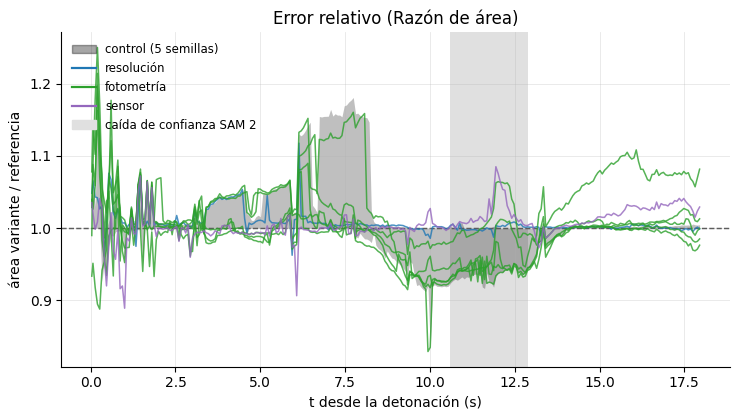

[banda] t en [0, 2) s: ancho max 0.157 | ancho mediano 0.041
[banda] t en [2, 10.6) s: ancho max 0.181 | ancho mediano 0.048
[banda] t en [10.6, 12.9) s: ancho max 0.084 | ancho mediano 0.064
[banda] t en [12.9, 99) s: ancho max 0.054 | ancho mediano 0.004


In [23]:
CORRER_BANDA     = False
SEMILLAS_CONTROL = [1, 2, 3, 4]
FRANJA_QUIEBRE   = (10.6, 12.9)

VARS_CTRL = F1.variantes_control(SEMILLAS_CONTROL)
_SUB      = F1.dir_experimento(CFG, "consistencia")
_CSV_BASE = CFG.ruta(1, "diagnosticos", _SUB, "consistencia.csv")
_CSV_CTRL = CFG.ruta(1, "diagnosticos", _SUB, "consistencia_control.csv")

if CORRER_BANDA:
    seg_val = F1.Segmentador(CFG.sam2_ckpt, CFG.sam2_cfg, CFG.dispositivo)
    filas_c, resumen_c, _ = F1.estudio_consistencia(
        CFG, masks_ref=masks, detector=detector, seg=seg_val, geo=GEO,
        par_det=PAR_DET, par_sam=PAR_SAM, fps=FPS, fin=FIN,
        pivote=CFG.pivot_frame,
        gsd_ref=GSD, pivote_ref_px=(PX, PY), forma_ref=FORMA,
        dir_frames=DIR_FRAMES, variantes=VARS_CTRL,
        firma=FIRMA_CONS, n_consenso=40, semilla=SEMILLA,
        guardar_mascaras=False)
    F0.guardar_csv(filas_c, F1.COLUMNAS_CONSISTENCIA, _CSV_CTRL)
    F1.tabla_consistencia(resumen_c)


def _leer_consistencia(ruta):
    with open(ruta, encoding="utf-8") as fh:
        return [[r["variante"], int(r["frame"]), float(r["t_s"]),
                 float(r["area_ref"]), float(r["area_var"]), float(r["razon_area"])]
                for r in csv.DictReader(fh)]


_filas = _leer_consistencia(_CSV_BASE)
if os.path.exists(_CSV_CTRL):
    _filas += _leer_consistencia(_CSV_CTRL)
else:
    print(f"[F1-8c] falta {F0.ruta_corta(_CSV_CTRL)}: la banda usa solo el control de F1-8.")

_filas_sin_geo = [r for r in _filas if F1.familia(r[0]) != "geometría"]
BANDA = F1.grafico_razon_area_banda(
    _filas_sin_geo, franja=FRANJA_QUIEBRE,
    ruta=CFG.ruta(1, "diagnosticos", _SUB, "razon_area_banda.png"))

_ancho = BANDA["max"] - BANDA["min"]
for _a, _b in [(0, 2), (2, 10.6), (10.6, 12.9), (12.9, 99)]:
    _k = (BANDA["t"] >= _a) & (BANDA["t"] < _b)
    if _k.any():
        print(f"[banda] t en [{_a}, {_b}) s: ancho max {_ancho[_k].max():.3f} | "
              f"ancho mediano {np.median(_ancho[_k]):.3f}")


## F1-9 — Anotación manual de la columna de gas

Herramienta de trazado.

| | |
|---|---|
| clic izq | añadir vértice |
| **clic der** | **zoom centrado ahí** (vuelve a acercar si ya hay zoom) |
| `c` | cerrar el polígono en curso |
| `+` / `-` · `f` | más / menos zoom · ver el cuadro completo |
| `z` | deshacer el último vértice |
| `x` | borrar el último polígono cerrado |
| `r` | reiniciar el frame |
| `ESPACIO` / `n` · `a` / `p` | siguiente · anterior |
| `g` · `q`/`ESC` | guardar · guardar y salir |

Guarda después de cada frame: cerrar la ventana no pierde nada, y volver a
correr la celda **continúa** donde ibas.

La salida es `datos/anotaciones.json` .

In [24]:
CREAR_GT = False      # <-- True abre la ventana de anotación

N_ANOTAR  = 12
_ks       = sorted(masks)
FRAMES_GT = [_ks[i] for i in
             np.unique(np.linspace(0, len(_ks) - 1, N_ANOTAR).round().astype(int))]
print("frames a anotar:", FRAMES_GT)

if CREAR_GT:
    ANN = F1.anotar_columna(CFG, FRAMES_GT, FORMA, fps=FPS)
else:
    ANN = F1.cargar_anotaciones(CFG)
    print(f"[gt] CREAR_GT=False. Frames anotados en disco: "
          f"{len(ANN.get('frames', {}))}")

frames a anotar: [249, 296, 346, 394, 444, 492, 542, 590, 640, 688, 738, 786]
[gt] CREAR_GT=False. Frames anotados en disco: 12


## F1-10 — SAM 2 contra el trazado manual


  frame    t (s)    area gt   area mod   razon    err %     IoU
---------------------------------------------------------------
    249     0.03     10,635     14,073   1.323    +32.3   0.747
    296     1.60     68,113     73,664   1.081     +8.2   0.885
    346     3.27    118,090    115,802   0.981     -1.9   0.955
    394     4.87    172,386    160,361   0.930     -7.0   0.912
    444     6.54    199,498    194,095   0.973     -2.7   0.962
    492     8.14    247,673    243,391   0.983     -1.7   0.959
    542     9.81    297,352    305,696   1.028     +2.8   0.904
    590    11.41    317,627    371,373   1.169    +16.9   0.826
    640    13.08    375,748    382,814   1.019     +1.9   0.919
    688    14.68    351,981    353,870   1.005     +0.5   0.933
    738    16.35    293,104    276,690   0.944     -5.6   0.913
    786    17.95    160,582    169,233   1.054     +5.4   0.848
---------------------------------------------------------------

  razon de area   mediana 1.012  [0.93

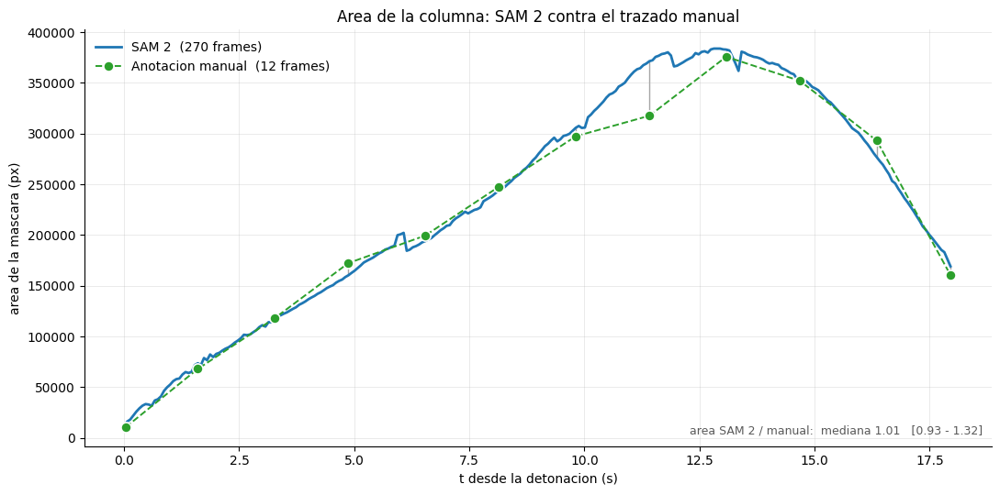

  area SAM 2 / manual: mediana 1.012 | min 0.930 | max 1.323
  de 12 frames anotados: 4 con el modelo por encima, 2 por debajo, 6 dentro de +-5%
[figura] resultados\1_deteccion_gas\diagnosticos\Ground truth\comparacion_mascaras.png


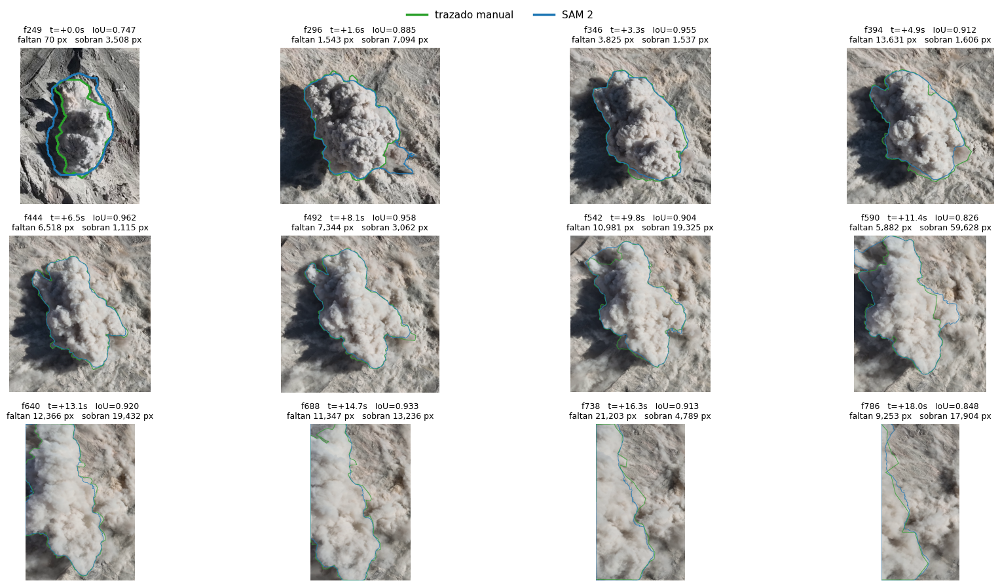

  12 frames comparados


In [25]:
N_PANELES = 12       
RECORTAR  = True     

if ANN.get("frames"):
    _SUB = F1.dir_experimento(CFG, "gt")

    F1.exito_por_area(ANN, masks, FORMA, fps=FPS, pivote=PIVOTE,
                      tol=max(2, SKIP))

    F1.grafico_area_vs_tiempo(
        ANN, masks, FORMA, fps=FPS, pivote=PIVOTE, tol=max(2, SKIP),
        ruta=CFG.ruta(1, "diagnosticos", _SUB, "area_vs_tiempo.png"))

    F1.figura_comparacion_mascaras(
        CFG, ANN, masks, FORMA, fps=FPS, pivote=PIVOTE, tol=max(2, SKIP),
        n_max=N_PANELES, recortar=RECORTAR,
        ruta=CFG.ruta(1, "diagnosticos", _SUB, "comparacion_mascaras.png"))
else:
    print("Sin anotaciones.")

---

# FASE 2 — Reconstruccion 3D de la columna 


Reconstrucción por intersección de dos vistas: la **cámara del dron** y el
**sol**.

## F2-0 — ARRANQUE


In [26]:
CTX = F0.iniciar(run="")

CFG, VID              = CTX["CFG"], CTX["VID"]
FPS, N_FRAMES, FIN    = CTX["FPS"], CTX["N_FRAMES"], CTX["FIN"]
H_WORK, W_WORK, FORMA = CTX["H_WORK"], CTX["W_WORK"], CTX["FORMA"]
PF = CFG.pivot_frame

F0.exigir_sello(CFG, 1, "mascaras_gas.pkl")

[config] leida de resultados\config.json

raiz        : .
run         : (sin subcarpeta de version)
resultados  : resultados
video       : datos\DJI_20250815165143_0003_V.MP4
escala      : 0.5  |  pivote f248  |  GSD None m/px
video   : 3840x2160 | 29.97 fps | 787 frames
trabajo : 1920x1080 | analisis [248, 787)


{'video': 'DJI_20250815165143_0003_V.MP4',
 'mascaras': 270,
 'skip': 2,
 'firma': '0cdfb680',
 'pivot_frame': 248,
 'sombras': 579,
 'sombras_pre': 40}

## F2-1 — ESCENA: DEM · CÁMARA · SOL · PIVOTE


In [27]:
ESC = F2.preparar_escena(CFG)
PIVOTE, ORIGEN = ESC["pivote"], ESC["origen"]

RES_VOX     = 2.5      
RADIO_XY    = 150.0    
Z_REL_MIN   = -10.0
Z_REL_MAX   = 120.0
PASO_FRAMES = 20      

DEM:
  archivo   : (481, 561) celdas, res (12.499999999999998, 12.5) m, EPSG:32719
  ventana   : (480, 560) celdas (2.15 MB)
  elevacion : 2216 / 3373 m  (nan: 0.0%)

Camara:
  resolucion : 1920x1080  f=1350.0 px
  FOV        : 70.8 x 43.6 deg
  dron UTM   : E 509936.2  N 7533919.9  z 2963.6 m
  mirada     : azimut 208.3 deg | depresion 59.7 deg
  instante   : 2025-08-15 16:51:51  (UTC-4)
  sol        : azimut 294.13 deg | elevacion 18.59 deg
  vec_sol    : E -0.8650  N +0.3874  U +0.3189
  sombra hacia azimut 114.1 deg | largo = 2.97 x altura

geometria: geometria.json
pivote  : f248 | UTM E 509881.43 N 7533810.54 z 2760.97
sol     : az 294.13  elev 18.59
separacion entre vistas: 266 deg  (90 seria el optimo)


## F2-2 — MAPAS DE TERRENO + CORREDOR DE SOMBRA 


In [28]:
TER  = F2.mapas_terreno(ESC, CFG.dir_cache, CFG.usar_cache)
CORR = F2.corredor_sombra(ESC, TER, CFG.dir_cache, CFG.usar_cache,
                          h_max=160.0, paso=6.0, step=4)
print(f"\ntecho de altura medible por sombra ≈ "
      f"{F2.altura_limite_cuadro(ESC, TER):.0f} m")

cargado de cache: terreno_1920x1080_p2_s1.npz
  sin terreno 0.00%  |  auto-sombra 3.70%  |  5.80 px/m
cargado de cache: corredor_h160_p6_s4.npz
  memoria 44 MB | alcance 160 m = 476 m de sombra

techo de altura medible por sombra ≈ 55 m


## F2-3 — MÁSCARAS Y EVIDENCIA TERNARIA


In [29]:
UMBRAL_ESTATICA = 0.5
RADIO_ESTATICA  = 5
RADIO_GAS_DESC  = 3

MASK_GAS, _META_GAS = F0.cargar_mascaras(CFG.art_mascaras_gas)

if os.path.exists(CFG.art_mascaras_sombra):
    _sm, _META_SOM = F0.cargar_mascaras(CFG.art_mascaras_sombra)
    MASK_SOM = {int(f): (np.asarray(m) > 0) for f, m in _sm.items()}
    print(f"  sombra: {len(MASK_SOM)} frames  [f{min(MASK_SOM)} .. f{max(MASK_SOM)}]"
          f"  ({_META_SOM.get('metodo','?')})")
    del _sm
else:
    raise FileNotFoundError(
        f"Falta {CFG.art_mascaras_sombra}. Correr la Fase 1 para generar las máscaras de sombra.")

FRAMES_PRE  = sorted(f for f in MASK_SOM if f < PF)
FRAMES_GAS  = sorted(f for f in MASK_GAS if f >= PF)

KEYFRAMES   = FRAMES_GAS[::PASO_FRAMES]
if len(FRAMES_PRE) < 10:
    raise RuntimeError(
        f"Solo {len(FRAMES_PRE)} frames pre-tronadura en las máscaras de sombra. "
        f"Vuelve a correr la Fase 1 con un numero mayor.")

SOMBRA_EST, _ = F2.sombra_estatica(MASK_SOM, FRAMES_PRE, umbral=UMBRAL_ESTATICA)
SOMBRA_COL, EVID = F2.evidencia(KEYFRAMES, MASK_GAS, MASK_SOM, SOMBRA_EST,
                                CORR, ESC, TER, RADIO_ESTATICA, RADIO_GAS_DESC)

  sombra: 579 frames  [f208 .. f786]  (multicanal V6 (Arjomandi 2022))
  frames pre-tronadura : 40 [f208 .. f247]
  sombra estatica      : 5.22% del frame (umbral fraccion >= 0.5)
   frame   gas%  som_col%   ev:-1%
     249   0.68      0.09     8.65
     288   3.14      1.78    11.12
     328   4.89      2.54    12.80
     368   6.60      3.03    14.54
     408   8.50      3.69    16.62
     448   9.50      4.15    17.69
     488  11.53      4.69    19.77
     528  14.28      4.87    22.54
     568  16.49      4.82    24.86
     608  17.69      2.87    26.06
     648  17.45      1.36    25.72
     688  17.07      0.19    25.15
     728  14.34      0.00    22.40
     768  10.05      0.00    18.11
  sin sombra utilizable: [728, 768]


## F2-4 — GRILLA Y PRECÁLCULO DE PROYECCIONES


In [30]:
G = F2.crear_grilla_voxeles(PIVOTE, RADIO_XY, Z_REL_MIN, Z_REL_MAX,
                             RES_VOX, ESC["dem"]["Z_interp"])

_cp = os.path.join(CFG.dir_cache,
                   f"proy_r{RES_VOX}_R{RADIO_XY:.0f}_z{Z_REL_MIN:.0f}_{Z_REL_MAX:.0f}.npz")
PR = None
if CFG.usar_cache and os.path.exists(_cp):
    with np.load(_cp) as _z:
        if len(_z["uc"]) == len(G["P"]):
            PR = {k: _z[k] for k in _z.files}
    if PR is None:
        print(f"caché de otra grilla: se recalcula {os.path.basename(_cp)}")
    else:
        PR["prof_terreno"] = TER["prof_terreno"]
        print(f"cargado de caché: {os.path.basename(_cp)}")
if PR is None:
    PR = F2.precalcular(G, ESC["K"], ESC["H_c_w"], ESC["vec_sol"],
                          ESC["dem"]["Z_interp"], TER["XM"], TER["YM"], TER["ZM"],
                          ESC["W"], ESC["H"], t_max=900.0)
    np.savez_compressed(_cp, uc=PR["uc"], vc=PR["vc"], ok_c=PR["ok_c"],
                        us=PR["us"], vs=PR["vs"], ok_s=PR["ok_s"],
                        P_suelo=PR["P_suelo"])
    print(f"guardado: {F0.ruta_corta(_cp)}")

if G["P"][:, 2].max() > ESC["H_c_w"][2, 3]:
    print("Hay vóxeles por encima de la cámara. Bajar Z_REL_MAX.")

_ = F2.revisar_grilla(G, ESC, MASK_GAS, KEYFRAMES)

  centro   : E 509881.4  N 7533810.5  z terreno 2761.0 m
  grilla   : 121 x 121 x 53 = 775,973 celdas, res 2.5 m
  sobre terreno: 699,015 voxeles (90.1%)
  extension: +-150.0 m en XY | z rel [-10.0, 120.0] m
cargado de caché: proy_r2.5_R150_z-10_120.npz
  [OJO] en f448 el 2.5 % de la mascara de gas cae FUERA de la huella de la grilla.
        sube RADIO_XY (ahora 150 m) o Z_REL_MAX; si no, el hull sale recortado y parece correcto.


## F2-5 — CARVING SOBRE LOS KEYFRAMES


In [31]:
HULL_ENV, HULL_REV, TOPE = {}, {}, {}
print(f"  {'frame':>6} {'ENV':>9} {'REV':>9} {'h_tope':>8} {'sin_info':>9}")
for f in KEYFRAMES:
    r = F2.reconstruir(G, PR, ESC, MASK_GAS[f], EVID[f], SOMBRA_COL[f],
                       res_vox=RES_VOX)
    HULL_ENV[f], HULL_REV[f], TOPE[f] = r["env"], r["rev"], r["tope"]
    h = r["tope"]["h"] if r["tope"] else np.nan
    flag = "" if not r["tope"] else ("?" if r["tope"]["sin_ev"] else
                                     ("*" if r["tope"]["limitado"] else " "))
    print(f"  {f:>6} {r['env'].sum():>9,} {r['rev'].sum():>9,} "
          f"{h:>7.1f}{flag} {r['diag']['frac_sin_info']*100:>8.1f}%")

print("\n  * tope limitado por el borde del cuadro --> cota inferior")
print("  ? sin evidencia de sombra --> cota superior floja")
print("  sin_info = vóxeles vistos como gas cuya sombra no es observable")

   frame       ENV       REV   h_tope  sin_info
     249     1,945       312   120.0?     31.1%
     288     9,330     1,549    20.0      33.4%
     328    14,586     2,400    22.5      35.8%
     368    19,796     3,877    27.5      38.1%
     408    25,525     5,610    30.0      40.5%
     448    28,561     6,895    35.0      43.9%
     488    34,500     9,976    40.0      47.4%
     528    41,989    16,961    50.0      52.4%
     568    47,105    18,595    50.0*     59.4%
     608    48,618    14,392    45.0*     68.3%
     648    44,931    26,532   120.0?     72.8%
     688    41,665    23,408   120.0?     79.1%
     728    32,859    16,801   120.0?     84.0%
     768    21,465    10,712   120.0?     87.9%

  * tope limitado por el borde del cuadro --> cota inferior
  ? sin evidencia de sombra --> cota superior floja
  sin_info = vóxeles vistos como gas cuya sombra no es observable


## F2-6 — ALTURA POR SOMBRA SOBRE TODOS LOS FRAMES CON GAS


  techo medible por sombra ≈ 55 m 
evidencia para 256 frames nuevos...
  225/270  medidas 141
  270 frames con gas → 141 medidas usables | 83 tocando el borde (descartadas) | 45 sin sombra utilizable | 1 fuera de [3, 120] m
  ley de potencia: h = 9.22·(t+1)^0.67
  altura: 5.8 – 43.0 m


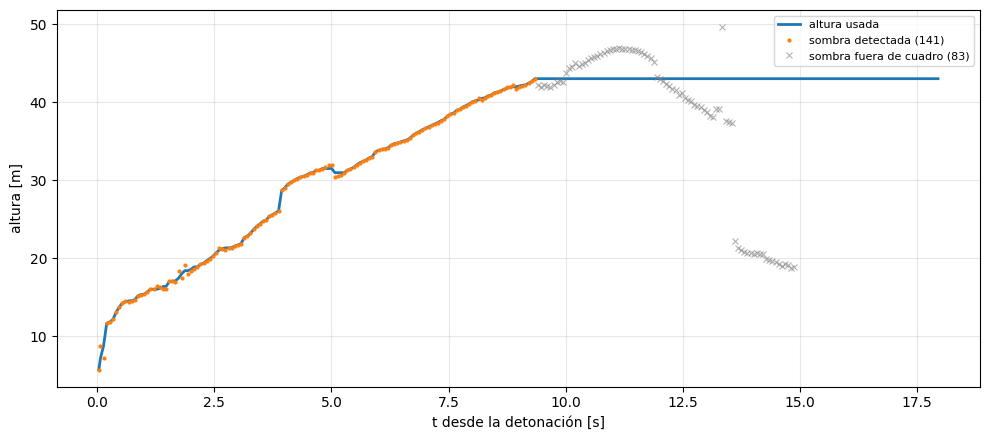

In [32]:
TALLADO_SOLAR = False
H_MIN_FIS, H_MAX_FIS = 3.0, 120.0

HLIM = F2.altura_limite_cuadro(ESC, TER)
print(f"  techo medible por sombra ≈ {HLIM:.0f} m ")

FRAMES_SIM = FRAMES_GAS[:]
falta = [f for f in FRAMES_SIM if f not in SOMBRA_COL]
if falta:
    print(f"evidencia para {len(falta)} frames nuevos...")
    _sc, _ev = F2.evidencia(falta, MASK_GAS, MASK_SOM, SOMBRA_EST, CORR, ESC,
                            TER, RADIO_ESTATICA, RADIO_GAS_DESC, verbose=False)
    SOMBRA_COL.update(_sc); EVID.update(_ev)

H_PUNTA = np.full(len(FRAMES_SIM), np.nan) 
H_CORTE = np.full(len(FRAMES_SIM), np.nan) 
n_sin, n_rango = 0, 0
for i, f in enumerate(FRAMES_SIM):
    occ, _ = F2.carving(G, PR, MASK_GAS[f], EVID[f], usar_sombra=TALLADO_SOLAR)
    occ, _ = F2.regularizar(G, occ, cerrar=1, abrir=1, solo_mayor=True)
    eje = None
    if occ.sum() >= 8:
        _, _R0, eje = F2.revolucion(G, occ, ESC["n_cam"], ESC["n_sol"], k_top=None)
    if SOMBRA_COL[f].sum() < 200:
        n_sin += 1
        continue
    ap = F2.altura_por_punta_eje(SOMBRA_COL[f], TER["XM"], TER["YM"],
                                 TER["ZM"], PIVOTE, ESC["d_h"], ESC["tan_e"],
                                 ESC["W"], eje=eje, z_niveles=G["vz"])
    if ap is None:
        n_sin += 1
    elif not (H_MIN_FIS <= ap["h"] <= H_MAX_FIS):
        n_rango += 1
    elif ap["truncada"]:
        H_CORTE[i] = ap["h"]
    else:
        H_PUNTA[i] = ap["h"]
    if (i+1) % 25 == 0:
        print(f"  {i+1}/{len(FRAMES_SIM)}  medidas {np.isfinite(H_PUNTA[:i+1]).sum()}",
              end="\r")

n_ok, n_cor = int(np.isfinite(H_PUNTA).sum()), int(np.isfinite(H_CORTE).sum())
print(f"\n  {len(FRAMES_SIM)} frames con gas → {n_ok} medidas usables | "
      f"{n_cor} tocando el borde (descartadas) | "
      f"{n_sin} sin sombra utilizable | {n_rango} fuera de [{H_MIN_FIS:.0f}, "
      f"{H_MAX_FIS:.0f}] m")
if n_cor > n_ok:
    print("¡Alerta!: La mayoría de las sombras se sale del cuadro")
if n_ok and np.nanmax(H_PUNTA) > HLIM:
    print(f"¡Alerta!: Hay medidas por encima del techo del cuadro ({HLIM:.0f} m)")

T, H_SUAVE, ley = F2.curva_altura(FRAMES_SIM, H_PUNTA, FPS, PF)
K_TOP = {f: int(np.argmin(np.abs(G["vz"] - (PIVOTE[2] + H_SUAVE[i]))))
         for i, f in enumerate(FRAMES_SIM)}

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(T, H_SUAVE, "-", lw=2, label="altura usada")
_m = np.isfinite(H_PUNTA)
ax.plot(T[_m], H_PUNTA[_m], ".", ms=4, color="tab:orange",
        label=f"sombra detectada ({n_ok})")
_m = np.isfinite(H_CORTE)
if _m.any():
    ax.plot(T[_m], H_CORTE[_m], "x", ms=4, mew=.8, color="tab:gray", alpha=.6,
            label=f"sombra fuera de cuadro ({n_cor})")
ax.set_xlabel("t desde la detonación [s]"); ax.set_ylabel("altura [m]")
ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(CFG.ruta(2, "altura_columna.png"), dpi=120); plt.show()


## F2-7 — VALIDACIÓN VISUAL SOBRE EL FRAME REAL


  frames mostrados: [249, 428, 606, 786]


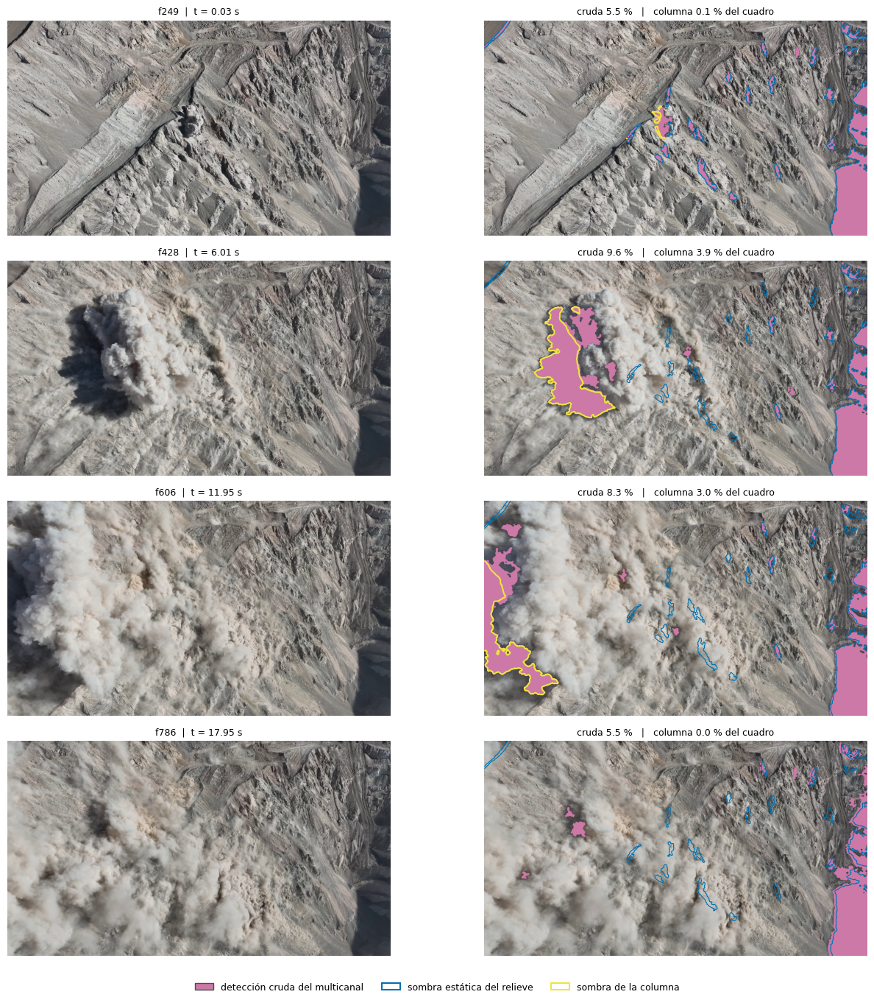

In [33]:
N_SOM = 4
_disp = sorted(SOMBRA_COL)
_ix = np.unique(np.linspace(0, len(_disp) - 1, N_SOM).round().astype(int))
FRAMES_SOM = [_disp[i] for i in _ix]
print(f"  frames mostrados: {FRAMES_SOM}")

COL_CRUDA, COL_EST, COL_COL = "#CC79A7", "#0072B2", "#F0E442"
LW_EST, LW_COL = 0.8, 1.4

from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
_RGB_CRUDA = np.array(to_rgb(COL_CRUDA), np.float32) * 255

fig, axs = plt.subplots(len(FRAMES_SOM), 2, figsize=(14, 3.4*len(FRAMES_SOM)))
axs = np.atleast_2d(axs)
with F0.LectorVideo(CFG.video, CFG.escala) as lec:
    for r, f in enumerate(FRAMES_SOM):
        base = lec[f]
        base = base[:, :, ::-1] if base is not None else np.zeros((ESC["H"], ESC["W"], 3), np.uint8)
        vis = base.astype(np.float32).copy()
        vis[MASK_SOM[f]] = _RGB_CRUDA
        vis = np.clip(vis, 0, 255).astype(np.uint8)
        axs[r, 0].imshow(base)
        axs[r, 0].set_title(f"f{f}  |  t = {(f-PF)/FPS:.2f} s", fontsize=9)
        axs[r, 1].imshow(vis)
        if SOMBRA_EST.any():
            axs[r, 1].contour(SOMBRA_EST.astype(np.float32), levels=[0.5],
                              colors=[COL_EST], linewidths=LW_EST)
        if SOMBRA_COL[f].any():
            axs[r, 1].contour(SOMBRA_COL[f].astype(np.float32), levels=[0.5],
                              colors=[COL_COL], linewidths=LW_COL)
        axs[r, 1].set_title(f"cruda {MASK_SOM[f].mean()*100:.1f} %   |   "
                            f"columna {SOMBRA_COL[f].mean()*100:.1f} % del cuadro",
                            fontsize=9)
        for c in range(2):
            axs[r, c].axis("off")

fig.legend(handles=[Patch(facecolor=COL_CRUDA, edgecolor="0.3", label="detección cruda del multicanal"),
                    Patch(facecolor="none", edgecolor=COL_EST, linewidth=1.5, label="sombra estática del relieve"),
                    Patch(facecolor="none", edgecolor=COL_COL, linewidth=1.5, label="sombra de la columna")],
           loc="lower center", ncol=3, frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(CFG.ruta(2, "sombra_multicanal.png"), dpi=120); plt.show()

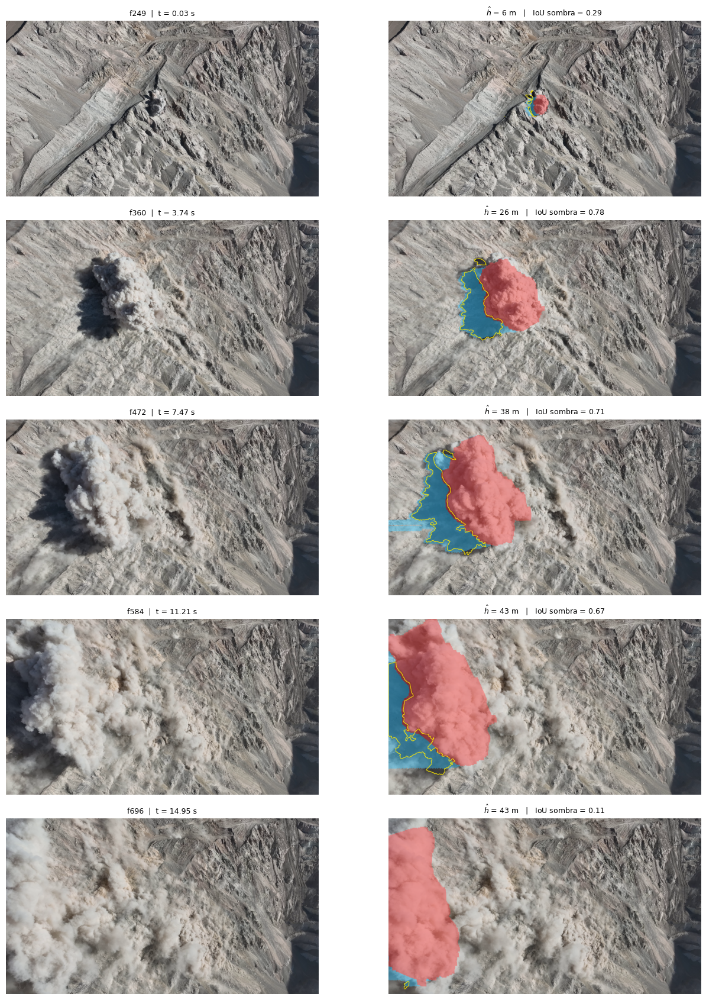

In [34]:
STEP_SOMBRA   = 4      
TALLADO_SOLAR = True
N_VIS         = 5

_utiles = [f for f in FRAMES_SIM if SOMBRA_COL[f].sum() >= 200]
if len(_utiles) < N_VIS:
    print(f" ¡Alerta!: solo {len(_utiles)} frames con sombra usable")
    _utiles = _utiles or FRAMES_SIM
_idx = np.unique(np.linspace(0, len(_utiles) - 1, N_VIS).round().astype(int))
FRAMES_VIS = [_utiles[i] for i in _idx]

fig, axs = plt.subplots(len(FRAMES_VIS), 2, figsize=(14, 3.4*len(FRAMES_VIS)))
axs = np.atleast_2d(axs)
with F0.LectorVideo(CFG.video, CFG.escala) as lec:
    for r, f in enumerate(FRAMES_VIS):
        rec  = F2.reconstruir(G, PR, ESC, MASK_GAS[f], EVID[f], k_top=K_TOP[f],
                              usar_sombra=TALLADO_SOLAR, res_vox=RES_VOX)
        hull = rec["rev"]
        base = lec[f]
        base = base[:, :, ::-1] if base is not None else np.zeros((ESC["H"], ESC["W"], 3), np.uint8)
        sil = F2.silueta(G, hull, ESC["K"], ESC["H_c_w"], ESC["W"], ESC["H"])
        sp  = F2.sombra_proyectada(G, hull, TER["XM"], TER["YM"], TER["ZM"],
                                   ESC["vec_sol"], step=STEP_SOMBRA, paso=RES_VOX*0.6)
        iou_som = F2.comparar(sp, SOMBRA_COL[f], EVID[f] >= 0)["iou"]
        h_f = float(H_SUAVE[FRAMES_SIM.index(f)])
        vis = F2.superponer(base, sil, sp, SOMBRA_COL[f])
        axs[r, 0].imshow(base)
        axs[r, 0].set_title(f"f{f}  |  t = {(f-PF)/FPS:.2f} s", fontsize=9)
        axs[r, 1].imshow(vis)
        axs[r, 1].set_title(rf"$\hat{{h}}$ = {h_f:.0f} m   |   IoU sombra = {iou_som:.2f}",
                            fontsize=9)
        for c in range(2):
            axs[r, c].axis("off")
plt.tight_layout()
plt.savefig(CFG.ruta(2, "validacion_visual.png"), dpi=120); plt.show()


## F2-8 — VIDEO DE VALIDACIÓN SOBRE LA SECUENCIA COMPLETA


In [35]:
TALLADO_SOLAR = True

PASO_VIDEO   = 2     
STEP_SOM_VIS = 4     

FRAMES_VID = FRAMES_SIM[::PASO_VIDEO]
ALTURAS    = {f: float(H_SUAVE[i]) for i, f in enumerate(FRAMES_SIM)
              if f in set(FRAMES_VID)}
FPS_VID    = FPS / PASO_VIDEO    

print(f"  {len(FRAMES_VID)} frames  |  sombra a step={STEP_SOM_VIS}  |  "
      f"{FPS_VID:.1f} fps de salida")
RUTA_VID = F2.video_validacion(
    CFG, ESC, TER, G, PR, MASK_GAS, EVID, SOMBRA_COL, FRAMES_VID,
    CFG.ruta(2, "validacion.mp4"), fps=FPS_VID, k_top=K_TOP, alturas=ALTURAS,
    usar_sombra=TALLADO_SOLAR, res_vox=RES_VOX, step_sombra=STEP_SOM_VIS)


  135 frames  |  sombra a step=4  |  15.0 fps de salida
  120/135    490 s  (ETA    61 s)
[video] resultados\2_reconstruccion3d\validacion.mp4  |  135 frames en 539 s


# F2-9 — SERIE FINAL + EXPORT A BLENDER


In [36]:
PASO_EXPORT = 4   
SUAVIZAR, DECIMAR = 1, 0.5
FRAMES_EXP = FRAMES_SIM[::PASO_EXPORT]

HULLS_EXP, filas, MODOS = {}, [], {}
for i, f in enumerate(FRAMES_EXP):
    r = F2.reconstruir(G, PR, ESC, MASK_GAS[f], EVID[f], k_top=K_TOP[f],
                       usar_sombra=TALLADO_SOLAR, res_vox=RES_VOX)
    HULLS_EXP[f] = r["rev"]
    h = float(np.percentile(F2.altura_sobre_terreno(G, r["rev"]), 99)) if r["rev"].sum() else 0.0
    MODOS[f] = r["modo"]
    filas.append([int(f), f"{(f-PF)/FPS:.3f}", f"{h:.2f}",
                  f"{r['rev'].sum()*G['res']**3:.1f}", int(r["rev"].sum()),
                  r["modo"]])

F0.guardar_csv(filas, ["frame","t_s","h_m","vol_m3","n_vox","modo"],
                     CFG.art_serie_columna)
from collections import Counter
_c = Counter(MODOS.values())

RUTA_GLB = CFG.ruta(2, "gas_secuencia.glb")
RUTA_CAM = CFG.ruta(2, "camara_dron.json")
RUTA_TER = CFG.ruta(2, "terreno.glb")

F2.exportar_hulls_glb(HULLS_EXP, G, ORIGEN, RUTA_GLB, suavizar=SUAVIZAR,
                       color=(150, 148, 155, 110))
COLOR_GAS = F2.color_gas_por_frame(CFG, MASK_GAS, FRAMES_EXP)

CAM = F2.exportar_camara_json(ESC["K"], ESC["H_c_w"], ORIGEN, ESC["W"], ESC["H"],
                               RUTA_CAM, sol=ESC["sol"], fps=FPS,
                               keyframes=FRAMES_EXP, color_gas=COLOR_GAS)
if not os.path.exists(RUTA_TER):
    F2.exportar_terreno_glb(ESC["dem"], ORIGEN, RUTA_TER, radio=800.0,
                             ruta_textura=CFG.satelital if os.path.exists(CFG.satelital) else None,
                             paso=1)

import json
with open(RUTA_CAM, encoding="utf-8") as fh:
    d = json.load(fh)
d.update(pivot_frame=int(PF), paso_export=int(PASO_EXPORT),
         altura_m={int(f): float(H_SUAVE[FRAMES_SIM.index(f)]) for f in FRAMES_EXP},
         pivote_utm=[float(c) for c in PIVOTE])
with open(RUTA_CAM, "w", encoding="utf-8") as fh:
    json.dump(d, fh, indent=2, ensure_ascii=False)

print("  En Blender: Scripting -> Open -> "
      f"{F0.ruta_corta(CFG.ruta(2, 'blender_animar_gas.py'))} → Run Script (Alt+P).")
F0.sellar(CFG, 2, dict(frames=int(len(FRAMES_EXP)), paso_export=int(PASO_EXPORT),
                       res_vox=float(RES_VOX), pivot_frame=int(PF),
                       h_max_m=float(np.nanmax(H_SUAVE)),
                       sombra=str(_META_SOM.get("metodo", "?"))))

[csv] 68 filas -> resultados\2_reconstruccion3d\serie_columna.csv
  68 keyframes | 454,804 triangulos | 0 vacios | 9.1 MB
  origen UTM restado: E 509881.43 N 7533810.54 z 2760.97
  ejes en Blender: +X = Este, +Y = Norte, +Z = arriba
  escrito: resultados\2_reconstruccion3d\gas_secuencia.glb
  color del gas medido en 68 frames | mediana cruda R 182 G 179 B 175
  tono normalizado (el render pone la intensidad): R 1.00 G 0.98 B 0.96
  script de Blender: resultados\2_reconstruccion3d\blender_animar_gas.py
  En Blender: Scripting -> Open -> resultados\2_reconstruccion3d\blender_animar_gas.py → Run Script (Alt+P).


{'video': 'DJI_20250815165143_0003_V.MP4',
 'fases': {'0': {'video': 'DJI_20250815165143_0003_V.MP4',
   'procedencia': {'video': 'DJI_20250815165143_0003_V.MP4',
    'video_bytes': 434589456,
    'ts_inicio_video': 'nombre del archivo',
    'frame_data': 'telemetria djmd del MP4',
    'calibracion': 'fijada a mano: pivote_manual_20250815165143.pkl',
    'calibracion_esquema': 'v7.2',
    'pivot_frame': 'PENDIENTE: lo pone C0b (onset) o C1b (calibracion)',
    'insumos_externos': {'dem': 'DEM_mina.tif',
     'ortofoto': 'satelital_utm.tif',
     'bounds_mina': [506500.0, 7532500.0, 513500.0, 7538500.0]},
    'deriva_dron': {'este_m': 0.195,
     'norte_m': 0.155,
     'vertical_m': 0.599,
     'yaw_deg': 0.8,
     'gimbal_deg': 0.0,
     'horizontal_m': 0.249,
     'fps': 29.97}}},
  '1': {'video': 'DJI_20250815165143_0003_V.MP4',
   'mascaras': 270,
   'skip': 2,
   'firma': '0cdfb680',
   'pivot_frame': 248,
   'sombras': 579,
   'sombras_pre': 40},
  '2': {'video': 'DJI_202508151651

---

# FASE 3 — Viento por flujo optico


In [37]:
## F3-0 Arranque

CTX = F0.iniciar(run="")

CFG, VID              = CTX["CFG"], CTX["VID"]
FPS, N_FRAMES, FIN    = CTX["FPS"], CTX["N_FRAMES"], CTX["FIN"]
H_WORK, W_WORK, FORMA = CTX["H_WORK"], CTX["W_WORK"], CTX["FORMA"]
PF = CFG.pivot_frame

with open(CFG.art_geometria, "r", encoding="utf-8") as fh:
    GEOM = json.load(fh)
GSD_NAT = GEOM["gsd_nativo"]
print(f"gsd nativo (geometria.json) = {GSD_NAT:.5f} m/px   "
      f"[CFG.gsd_m_px = {CFG.gsd_m_px}"
      + (f" -> {100*(GSD_NAT/CFG.gsd_m_px-1):+.1f} %]" if CFG.gsd_m_px else "]"))

ALTURA_FIJA_M = 25.0

[config] leida de resultados\config.json

raiz        : .
run         : (sin subcarpeta de version)
resultados  : resultados
video       : datos\DJI_20250815165143_0003_V.MP4
escala      : 0.5  |  pivote f248  |  GSD None m/px
video   : 3840x2160 | 29.97 fps | 787 frames
trabajo : 1920x1080 | analisis [248, 787)
gsd nativo (geometria.json) = 0.08765 m/px   [CFG.gsd_m_px = None]


## F3-1 — CARGAR MASCARAS DE LA FASE 1


In [38]:
MAX_GAP = 3      

F0.exigir_sello(CFG, 1, "mascaras_gas.pkl")
masks, meta = F0.cargar_mascaras(CFG.art_mascaras_gas)
fkeys  = sorted(masks)
saltos = sorted(set(np.diff(fkeys).tolist()))
print(f"{len(masks)} mascaras [f{fkeys[0]}, f{fkeys[-1]}] | saltos: {saltos}")
print(f"meta: {meta}")

if saltos and max(saltos) > MAX_GAP:
    print(f"\n ¡Alerta!: Saltos de hasta {max(saltos)} > MAX_GAP={MAX_GAP}")
elif saltos and min(saltos) > 1:
    print(f"\n ¡Alerta!: Mascaras submuestreadas (salto {min(saltos)}).")

270 mascaras [f249, f786] | saltos: [1, 2]
meta: {'metodo': 'SAM2', 'firma': '0cdfb680', 'skip': 2, 'escala': 0.5, 'forma': (1080, 1920), 'pivot': 248, 'gsd_trabajo': 0.1753066213042818, 'pivote_px': (939.52, 520.96), 'ruido_base': 3.0, 'ancla': 250, 'nacimiento': 249, 'log_siembra': [(0, 250, 'puntos (bloque 0)', 'puntos CLIPSeg en f250 (16 pts)'), (1, 342, 'mascara', 'mascara de f342 (114182 px, 5.5% cob)'), (2, 442, 'mascara', 'mascara de f442 (192788 px, 9.3% cob)'), (3, 542, 'mascara', 'mascara de f542 (305696 px, 14.7% cob)'), (4, 642, 'mascara', 'mascara de f642 (381952 px, 18.4% cob)'), (5, 742, 'mascara', 'mascara de f742 (269342 px, 13.0% cob)')], 'busqueda': (250, 303), 'max_retroceso': 75}


## F3-2 — ESTIMACION


In [39]:
res = F3.estimar_viento(
    CFG.video, masks, fps=FPS, escala=CFG.escala, gsd_m_px=GSD_NAT,
    ventana_suave=15, ventana_dir=9, max_gap=MAX_GAP, min_px=200,
    etiqueta="SAM2 — opcion B", trayectoria="centroides")

t = (res["frames"] - PF) / FPS      
F3.guardar_serie(res, CFG.art_viento, pivot_frame=PF)

REF = dict(pares=269, v_media=51.7, v_max=201.7, dir_media=-176.8)
v = res["speed_px_s"]

Flujo optico (SAM2 — opcion B)...

----------------------------------------------------------
  SAM2 — opcion B
----------------------------------------------------------
  Pares validos   : 269
  Descartados     : {'gap_grande': 0, 'pocos_px': 0, 'lectura': 0}
  Velocidad media : 49.6 px/s  ->  4.35 m/s  (15.7 km/h)
  Velocidad maxima: 122.6 px/s
  Direccion media : -176.6 deg (0=E, 90=N en imagen)
  Trayectoria     : centroides
----------------------------------------------------------
[csv] 269 filas -> resultados\3_viento\viento_flujo_optico.csv


## F3-3 — CENTROIDE REAL DE LA COLUMNA


In [40]:
u_px, v_px = F3.centroide_mascaras(masks, res["frames"], forma=FORMA)
print(f"columna en imagen: u {np.nanmin(u_px):.0f}-{np.nanmax(u_px):.0f}  "
      f"v {np.nanmin(v_px):.0f}-{np.nanmax(v_px):.0f}")

columna en imagen: u 107-918  v 444-718


## F3-4 — La cámara georreferenciada

In [41]:
dem = F0.cargar_dem(CFG.dem)

cam = F0.CamaraGeo.desde_config(CFG, dem=dem)

with open(CFG.art_georreferencia, "r", encoding="utf-8") as fh:
    GEOREF0 = json.load(fh)
_esperado = (os.path.basename(CFG.video_nombre), os.path.basename(CFG.dem_nombre))
if (GEOREF0["video"], GEOREF0["dem"]) != _esperado:
    raise RuntimeError(
        f"georreferencia.json es de {GEOREF0['video']} sobre {GEOREF0['dem']} y "
        f"aqui se esta corriendo {_esperado[0]} sobre {_esperado[1]}. "
        f"Corre F0-7.")
print(f"[fase 0] georreferencia.json: {GEOREF0['video']} | "
      f"pivote UTM E {GEOREF0['pivote_utm'][0]:.1f} N {GEOREF0['pivote_utm'][1]:.1f} "
      f"z {GEOREF0['z_piso']:.1f} m")


  DEM EPSG:32719 | archivo (481, 561) | ventana (481, 561) | 12.5 m | z 2216-3373 m
  camara UTM : E 509936.1  N 7533919.9  z 2963.6
  mirada     : azimut 208.3 deg | depresion 59.7 deg
  u_img      -> azimut 298.3 deg
  v_img      -> azimut 28.3 deg
  escala en el plano del piso (m/px nativo): arriba 0.1134 | centro 0.0869 | abajo 0.0705  -> factor 1.61
[fase 0] georreferencia.json: DJI_20250815165143_0003_V.MP4 | pivote UTM E 509881.3 N 7533810.6 z 2761.0 m


## F3-5 — Verificación puntos cardinales

In [42]:
XM, YM, ZM = F0.raycast_dem(cam, dem, step=4)
print(f"  aciertos {100*np.isfinite(XM).mean():.1f}%  |  huella "
      f"{np.nanmax(XM)-np.nanmin(XM):.0f} x {np.nanmax(YM)-np.nanmin(YM):.0f} m")

print()
escala = F0.verificar_escala(cam, GSD_NAT)

_y = GEOREF0["yaw"]
if _y["optimo_deg"] is None:
    print("\n ¡Alerta!: yaw, la Fase 0 corrio sin georreferencia")
else:
    print(f"\n  yaw de metadatos {_y['metadatos_deg']:7.1f} deg")
    print(f"  yaw que maximiza la correlacion {_y['optimo_deg']:7.1f} deg")
    print(f"  diferencia {_y['optimo_deg']-_y['metadatos_deg']:+.1f} deg")

import pandas as pd
ctrl = pd.read_csv(CFG.ruta(0, "georreferencia_frame.csv"))
Xc, Yc, _ = F0.raycast_dem(cam, dem, step=1)
d = [np.hypot(Xc[int(r.px_y_trab), int(r.px_x_trab)] - r.utm_e,
              Yc[int(r.px_y_trab), int(r.px_x_trab)] - r.utm_n)
     for r in ctrl.itertuples() if int(r.px_y_trab) < cam.H and int(r.px_x_trab) < cam.W]
print(f"\n  control vs. georreferencia_frame.csv: dif. maxima {np.nanmax(d):.2f} m"
      f"   (esperado ~0.2 m)")


  aciertos 100.0%  |  huella 430 x 360 m

  rango camara->pivote (modelo camara + DEM) :   236.7 m
  rango implicado por el airblast (PPM_NAT)  :   236.7 m
  discrepancia : +0.0 m  (+0.0 %)
  a modo de contraste, un desfase real de 102 m en el DEM daria -37 % / +37 %

  yaw de metadatos  -151.7 deg
  yaw que maximiza la correlacion  -159.2 deg
  diferencia -7.5 deg

  control vs. georreferencia_frame.csv: dif. maxima 0.19 m   (esperado ~0.2 m)


## F3-6 — Altura del plano de advección

In [43]:
try:
    F0.exigir_sello(CFG, 2, "gas_secuencia.glb")
    RUTA_HULL = CFG.art_gas_glb
except RuntimeError as _e:
    print(f" ¡Alerta!: {_e}\n   -> sigo con el plano fijo a {ALTURA_FIJA_M:.0f} m")
    RUTA_HULL = None

z_adv, info_h = F3.resolver_altura(CFG, res["frames"], cam,
                                   ruta_glb=RUTA_HULL,
                                   altura_fija_m=ALTURA_FIJA_M)
alt = info_h["alt"]
print(f"  cota desde: {info_h['fuente']}")
print(f"  plano de adveccion: {z_adv.min()-cam.z_piso:.1f} - "
      f"{z_adv.max()-cam.z_piso:.1f} m sobre el piso")


  68 keyframes [f249, f784] | confiables 68
  centroide U: 2.4 - 25.5 m sobre el piso (0.54 del tope)
  altura: hull 3D, tramo confiable f249-784
  cota desde: hull 3D de la Fase 2
  plano de adveccion: 4.9 - 25.3 m sobre el piso


## F3-7 — Georreferenciación

Por cada par: se toma el píxel del centroide, se avanza `eps` píxeles en la
dirección que midió el flujo óptico, se mapean **ambos** puntos al plano de
advección y se diferencia. De ahí salen el azimut geográfico y los metros por
píxel que corresponden *a esa posición y esa dirección*.

| | significado | quién la usa |
|---|---|---|
| **HACIA** | hacia dónde se mueve el humo | flujo óptico |
| **DESDE** | de dónde viene el viento | DMC, meteorología |

`DESDE = HACIA + 180`.

In [44]:
geo = F3.georreferenciar(res, cam, u_px, v_px, z_adv)
print(f"escala local aplicada: {np.nanmin(geo['m_por_px']):.4f} - "
      f"{np.nanmax(geo['m_por_px']):.4f} m/px")

escala local aplicada: 0.0626 - 0.1020 m/px


## F3-8 — Ventana de viento establecido

In [45]:
T_INI, T_FIN, T_FIN_VEL, diag = F3.detectar_ventana(
    res, t, umbral_deriva=5.0, sostener=2.0,
    frac_textura=0.30, margen_borde=0.10, frac_recorte=0.02)

print()
r_dir = F3.resumen_ventana(geo, t, T_INI, T_FIN,     "direccion")
r_vel = F3.resumen_ventana(geo, t, T_INI, T_FIN_VEL, "velocidad")

  A) columna dejo de subir   (|w|/|u| < 0.30)  : sin hull 3D
  B) direccion dejo de girar (< 5 deg/s)      : t = 7.07 s
  -> t_ini = 7.07 s  (el mas tardio de los dos)
  C) textura bajo 0.30 (paridad 0.50)   : t = 9.88 s
  D) frente a < 108 px del borde   : t = 10.34 s
  -> t_fin = 9.88 s  (el mas temprano de los dos)
     [diag] el area de mascara nunca cae bajo el umbral (SAM2 sigue segmentando la nube diluida)

  direccion  t = [7.1, 9.9] s   n = 43
    HACIA  108.1 deg  |  DESDE  288.1 deg   (dispersion 0.6 deg)
    velocidad 6.82 m/s  (mediana 6.86, rango 6.25-7.21)
  velocidad  t = [7.1, 9.9] s   n = 43
    HACIA  108.1 deg  |  DESDE  288.1 deg   (dispersion 0.6 deg)
    velocidad 6.82 m/s  (mediana 6.86, rango 6.25-7.21)


## F3-9 — Sensibilidad a la altura


In [46]:
SENS = F3.sensibilidad_altura(res, cam, u_px, v_px, z_adv, t,
                              deltas=(-15, -10, -5, 0, 5, 10, 15),
                              t_ini=T_INI, t_fin=T_FIN_VEL)
BANDA_VEL = (min(f[3] for f in SENS), max(f[3] for f in SENS))

Z_MEDIA = float(np.mean(z_adv[(t >= T_INI) & (t <= T_FIN_VEL)]) - cam.z_piso)
print(f"  banda por altura: {BANDA_VEL[0]:.2f} - {BANDA_VEL[1]:.2f} m/s "
      f"(+-15 m sobre los {Z_MEDIA:.1f} m del plano en la ventana)")

   dz (m)    HACIA    DESDE   vel m/s
      -15    108.1    288.1      7.38
      -10    108.1    288.1      7.19
       -5    108.1    288.1      7.01
        0    108.1    288.1      6.82
        5    108.1    288.1      6.63
       10    108.1    288.1      6.44
       15    108.1    288.1      6.25
  banda por altura: 6.25 - 7.38 m/s (+-15 m sobre los 22.1 m del plano en la ventana)


## F3-10 — Concentración direccional (von Mises)

mu(vMF) vs eje PCA : mediana 1.0 deg  |  p90 2.5 deg
kappa > 9 sostenido 2 s : t = 5.34 s   <- T_INI = 7.07 s (criterio B)
kappa > 10 sostenido 2 s : t = 5.47 s
kappa en la ventana: mediana 11.8  (sigma ~ 16.7 deg)  |  rango 10.6 - 12.9
kappa despues      : mediana 12.7  |  maximo de la serie 14.5 en t = 13.28 s
  -> resultados\3_viento\von_mises.png


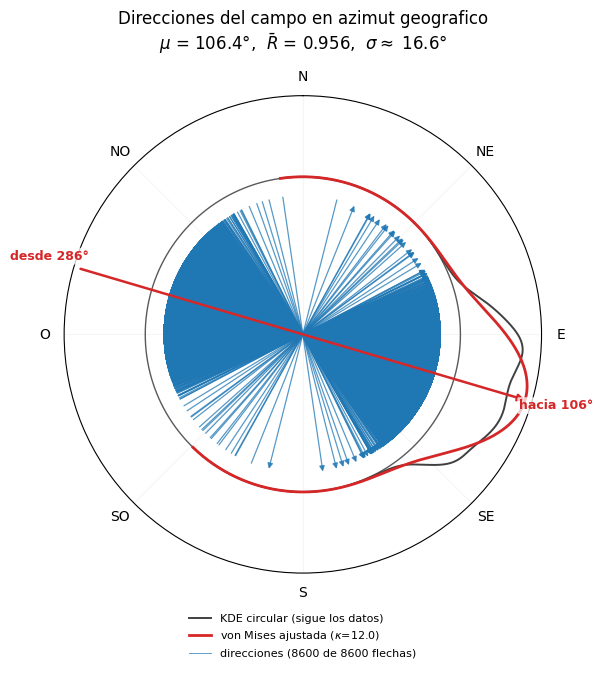


Diagnóstico bimodal:
  modos en 158.0 y 175.5 deg  |  sep 17.5 deg, alto 0.91, dip 0.04
  -> unimodal  (umbrales dip>0.30, alto>0.25, sep>15 deg)


In [47]:
mv = (t >= T_INI) & (t <= T_FIN)

d_pca = (res["vmf_mu_deg"] - res["angle_pca_deg"] + 180.0) % 360.0 - 180.0
print(f"mu(vMF) vs eje PCA : mediana {np.median(np.abs(d_pca[mv])):.1f} deg  |  "
      f"p90 {np.percentile(np.abs(d_pca[mv]), 90):.1f} deg")

for u in (9.0, 10.0):
    tk = F3._primer_sostenido(t, res["vmf_kappa"], u, 2.0, sentido="mayor")
    print(f"kappa > {u:.0f} sostenido 2 s : t = {tk:.2f} s"
          f"{'   <- T_INI = %.2f s (criterio B)' % T_INI if u == 9.0 else ''}")

k_in, k_out = res["vmf_kappa"][mv], res["vmf_kappa"][t > T_FIN]
print(f"kappa en la ventana: mediana {np.median(k_in):.1f}  "
      f"(sigma ~ {np.degrees(np.median(k_in)**-0.5):.1f} deg)  |  "
      f"rango {k_in.min():.1f} - {k_in.max():.1f}")
if k_out.size:
    print(f"kappa despues      : mediana {np.median(k_out):.1f}  "
          f"|  maximo de la serie {res['vmf_kappa'].max():.1f} "
          f"en t = {t[res['vmf_kappa'].argmax()]:.2f} s")

fig, VMF = F3.graficar_von_mises(res, t, t_ini=T_INI, t_fin=T_FIN, mostrar_kde =True, geo=geo,
                                 ruta_png=CFG.ruta(3, "von_mises.png"))
plt.show()

print("\nDiagnóstico bimodal:")
BIM = F3.diagnostico_bimodal(res, t, t_ini=T_INI, t_fin=T_FIN)

## F3-11 — Figuras

[fig] resultados\3_viento\wind_imagen.png


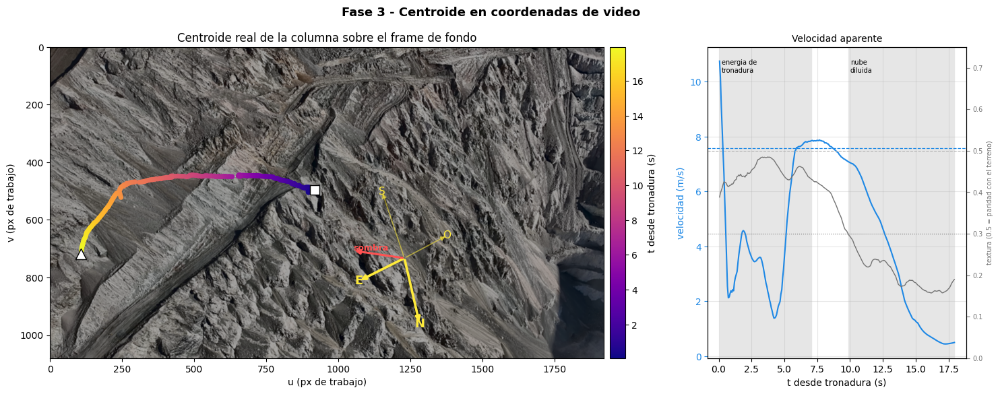

[fig] resultados\3_viento\validacion_dem.png


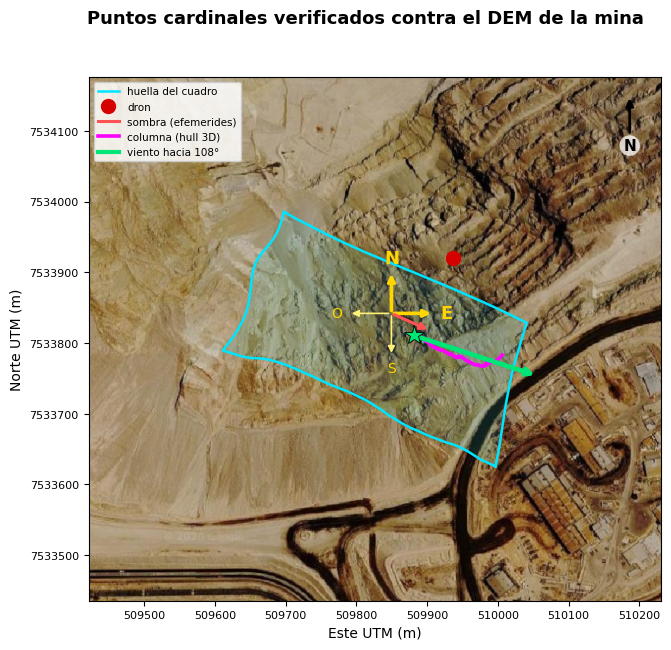

In [48]:
bg = cv2.imread(CFG.ruta(0, "bg_color.png"))

F3.graficar(res, FPS, PF, u_px=u_px, v_px=v_px, bg=bg, cam=cam, dem=dem,
            t_ini=T_INI, t_fin=T_FIN, diag=diag,
            ruta_png=CFG.ruta(3, "wind_imagen.png"))
plt.show()

F3.graficar_validacion_dem(cam, dem, bg, XM, YM, ZM, geo=geo, t=t,
                           t_ini=T_INI, t_fin=T_FIN, alt=alt, escala=escala,
                           ruta_ortofoto=CFG.satelital,
                           ruta_png=CFG.ruta(3, "validacion_dem.png"))
plt.show()

## F3-12 — Salida

| archivo | columnas |
|---|---|
| `viento_video.csv` | `frame`, `vel_px_frame`, `dir_video_deg` |
| `viento_mundo.csv` | `frame`, `vel_ms`, `dir_desde_deg` |

**Convenciones**, que van en el nombre de la columna para que el archivo se
explique solo:

- `vel_px_frame` — píxeles **nativos** (4K) por frame.
- `dir_video_deg` — 0 = hacia la derecha del cuadro, creciendo en sentido
  **horario en pantalla**. No son puntos cardinales.
- `vel_ms` — m/s horizontales sobre el plano de advección.
- `dir_desde_deg` — azimut meteorológico **DESDE**: de dónde viene el viento,
  0 = Norte, horario. Misma convención que la columna `dd` de la DMC.

In [49]:
SOLO_VENTANA = False    # True = escribe solo las filas de la ventana de viento

calidad = F3.banderas_calidad(CFG, cam, geo, t, T_INI, T_FIN, T_FIN_VEL,
                              info_h, escala=escala, diag=diag,
                              res=res, fps=FPS,
                              deriva=F0._leer_procedencia(CFG)
                                       .get("fases", {}).get("0", {})
                                       .get("procedencia", {}).get("deriva_dron"))
F3.guardar_serie_geo(geo, t, CFG.ruta(3, "viento_georreferenciado.csv"),
                     calidad=calidad)
F0.sellar(CFG, 3, {"calidad": calidad["calidad"], "banderas": calidad["banderas"]})


_ = F3.exportar_series_simples(
    res, t, FPS,
    ruta_video_csv = CFG.ruta(3, "viento_video.csv"),
    geo            = geo,
    ruta_mundo_csv = CFG.ruta(3, "viento_mundo.csv"),
    t_ini=T_INI, t_fin=T_FIN, t_fin_vel=T_FIN_VEL,
    solo_ventana=SOLO_VENTANA)

[csv] 269 filas -> resultados\3_viento\viento_georreferenciado.csv
  calidad: ok
[csv] 270 filas -> resultados\3_viento\viento_video.csv
[csv] 270 filas -> resultados\3_viento\viento_mundo.csv
  ventana de viento establecido: t = [7.1, 9.9] s
    video : 2.888 px/frame   dir 171.8 deg (0 = derecha, horario en pantalla)
    mundo : 6.817 m/s        DESDE 288.1 deg (0 = Norte, horario)
    [ojo] la fila PROMEDIO no es el promedio de las filas de arriba: se calcula solo en la ventana


## F3-13 — VIDEO DE DIAGNOSTICO DEL FLUJO


[video] 269 frames a 14.99 fps (paso 2) -> resultados\3_viento\flujo_optico.mp4
[fig] 6 paneles -> resultados\3_viento\flujo_optico_paneles.png


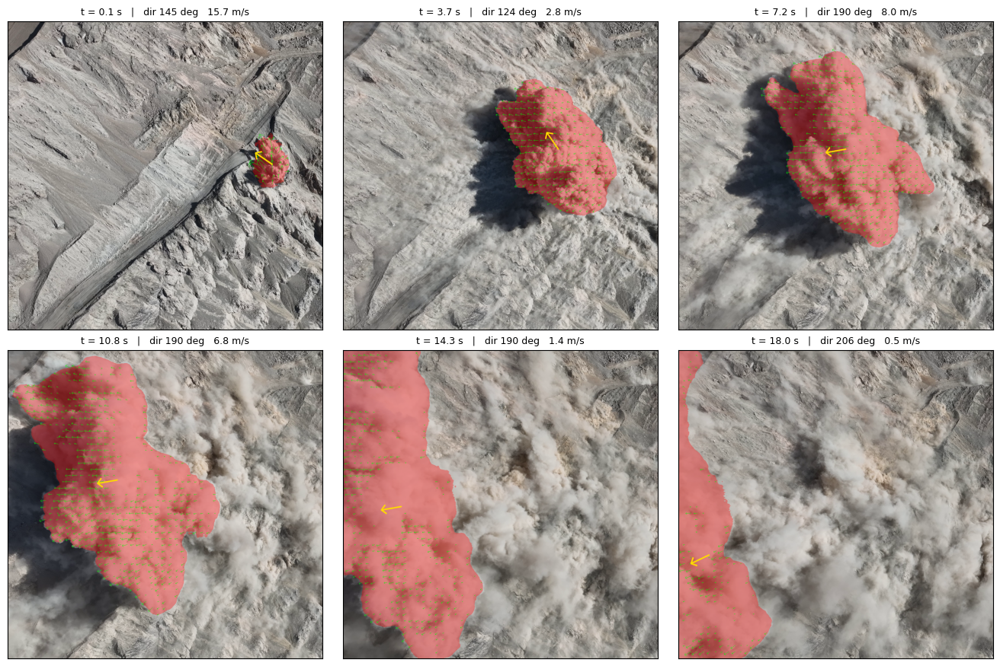

In [50]:
_, fig = F3.video_flujo(CFG.video, masks, CFG.ruta(3, "flujo_optico.mp4"),
                        fps=FPS, escala=CFG.escala, gsd_m_px=GSD_NAT,
                        max_gap=MAX_GAP, paso_grilla=22, mag_min=0.6,
                        escala_flecha=4.0,
                        n_paneles=6, cols=3, pivot_frame=PF,
                        ruta_png=CFG.ruta(3, "flujo_optico_paneles.png"))
plt.show()

## F3-14 — Contraste con las estaciones meteorológicas


INSTANTE DE LA TRONADURA
  primer frame del video : 2025-08-15 16:51:43 (America/Santiago)   <- nombre del archivo
  airblast en el clip    : frame 248.000 / 29.970 fps =  8.275 s   <- T0_SUBFRAME (airblast)
  INSTANTE DE TRONADURA  : 2025-08-15 16:51:51.274 (America/Santiago)
  la estacion mas cercana en el tiempo esta a 8 min; la etiqueta horaria del portal vale +-1 h

ESTACIONES
  DMC_Chorrillos          : 2 archivo(s) [carpeta]  2025-08.xls, 2026-04.xls
  SINCA_PVergaraKeller    : 2 archivo(s) [carpeta]  datos_DIR_121130_260813.csv, datos_VEL_121130_260813.csv
  Chorrillos (DMC): 2 archivos mensuales -> 1464 instantes unicos
  Chorrillos (DMC) (DMC): 1464 registros | 2025-07-31 .. 2026-04-30 (hora local)
    huecos: direccion 0 (0.0 %), velocidad 0 (0.0 %)
    velocidad cuantizada a nudos enteros: pasos de 0.51 m/s
    meses: 2025-07, 2025-08, 2026-03, 2026-04
    SIN DATOS en: 2025-09, 2025-10, 2025-11, 2025-12, 2026-01, 2026-02
  P.Vergara Keller (SINCA) (SINCA): 120119 registro

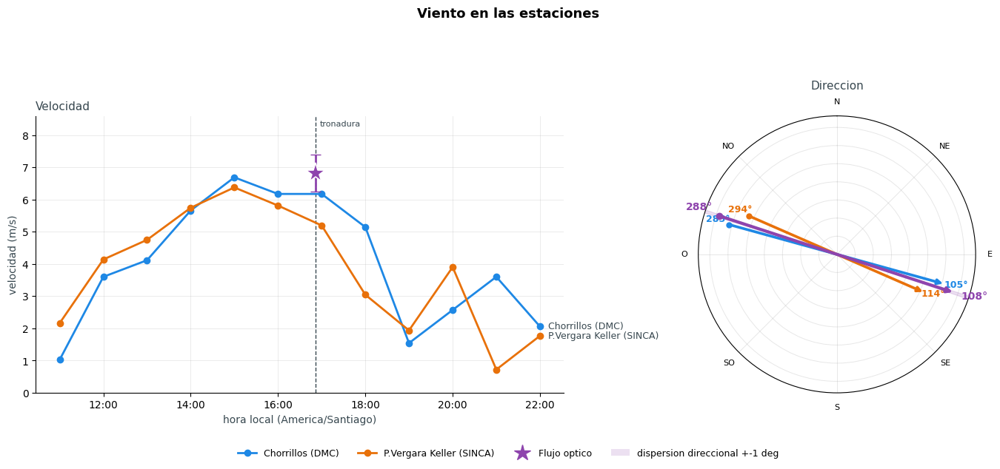

In [51]:
HORAS_VENTANA = 6.0     
Z_REF         = 10.0    

print("\nINSTANTE DE LA TRONADURA")
EV = F3.instante_tronadura(CFG, fps=FPS, geometria=GEOM,
                           procedencia=F0._leer_procedencia(CFG))

print("\nESTACIONES")
estaciones = F3.cargar_estaciones(CFG.dir_datos, tz_local=CFG.tz_local,
                                  ts_evento=EV["ts"], margen_h=HORAS_VENTANA)

import json as _json
_cob = {"evento": EV["ts"].isoformat(),
        "estaciones": [{"nombre": e["nombre"], "fuente": e["fuente"],
                        "archivos": e.get("archivos"),
                        "rango": [e["ts"][0].isoformat(), e["ts"][-1].isoformat()],
                        "cubre_evento": bool(e.get("cobertura", {}).get("ok"))}
                       for e in estaciones]}
with open(CFG.ruta(3, "estaciones_cobertura.json"), "w", encoding="utf-8") as _fh:
    _json.dump(_cob, _fh, indent=2, ensure_ascii=False)

if estaciones:
    z_pluma = float(np.mean(z_adv[(t >= T_INI) & (t <= T_FIN_VEL)]) - cam.z_piso)

    print("\nCOMPARACION")
    comp = F3.comparar_estacion(estaciones, EV["ts"],
                                desde_optico=r_dir["desde"],
                                vel_optica=r_vel["vel_media"],
                                z_pluma=z_pluma, z_ref=Z_REF,
                                origen_utm=cam.origen_utm)

    F3.graficar_estaciones(estaciones, EV["ts"],
                           desde_optico=r_dir["desde"],
                           vel_optica=r_vel["vel_media"],
                           z_pluma=z_pluma, z_ref=Z_REF, horas=HORAS_VENTANA,
                           banda_vel=BANDA_VEL,
                           dispersion_dir=r_dir["dispersion"],
                           ruta_png=CFG.ruta(3, "estaciones.png"))
    plt.show()
else:
    print("  (ninguna estacion cargo. Revisar datos/estaciones/: una carpeta por\n"
          "   estacion.)")

In [52]:
# F3-15 — DEGENERACION GEOMETRICA: separacion entre el ascenso proyectado y la direccion medida.
UMBRAL_DELTA = 45.0

A = cam.a_plano(u_px, v_px, z_adv)
B = A.copy(); B[:, 2] += 1.0
pa, _ = cam.a_pixel(A)
pb, _ = cam.a_pixel(B)
d_up   = pb - pa
alfa_up = np.degrees(np.arctan2(d_up[:, 1], d_up[:, 0])) % 360.0

ang_img = np.asarray(geo["angulo_imagen"], float) % 360.0
vel     = np.asarray(geo["vel_ms"], float)
m       = (t >= T_INI) & (t <= T_FIN)

a_med  = F3.media_circular_pond(ang_img[m], vel[m])
up_med = F3.media_circular_deg(alfa_up[m]) % 360.0
dif    = abs(a_med - up_med) % 360.0
DELTA  = min(dif, 360.0 - dif)

print(f"  direccion medida (imagen) : {a_med:7.1f} deg")
print(f"  ascenso puro proyectado   : {up_med:7.1f} deg   "
      f"(rango en la ventana {np.nanmin(alfa_up[m]):.1f} - {np.nanmax(alfa_up[m]):.1f})")
print(f"  separacion delta          : {DELTA:7.1f} deg   "
      f"(umbral {UMBRAL_DELTA:.0f})")
print()
if DELTA < UMBRAL_DELTA:
    print("  DEGENERADA: el ascenso y la deriva horizontal se proyectan sobre")
    print("  direcciones similares. La estimacion no es utilizable como viento.")
else:
    print("  Utilizable: el ascenso esta bien separado del eje dominante, asi que")
    print("  la proyeccion sobre e_t lo suprime.")


  direccion medida (imagen) :   171.8 deg
  ascenso puro proyectado   :   243.4 deg   (rango en la ventana 239.1 - 247.1)
  separacion delta          :    71.6 deg   (umbral 45)

  Utilizable: el ascenso esta bien separado del eje dominante, asi que
  la proyeccion sobre e_t lo suprime.


---

# FASE 4 — Concentracion por adveccion-difusion


La solución de la ecuación de advección-difusión para una emisión instantánea es
lineal en la masa emitida $Q$. El video mide la geometría de la nube, no $Q$, así
que la fase entrega la concentración normalizada

$$\chi = \frac{C}{Q}\qquad[\mathrm{m^{-3}}]$$


## Estructura

| Paso | Entrada | Salida |
|---|---|---|
| 1 | máscaras, geometría, DEM | ventana de trabajo y cámara georreferenciada |
| 2 | máscaras + viento | $\sigma_x(t)$, $\sigma_y(t)$ en metros, sobre el plano de advección |
| 3 | hull 3D de la Fase 2 | $H(t)$, $\sigma_z(t)$, y $\sigma_x,\sigma_y$ con la oblicuidad descontada |
| 4 | los anteriores | $\chi(t)$ en el centro de la nube, $z=H(t)$ |
| 5 | $\chi$ + $Q$ hipotéticas | $C = Q\,\chi$ en µg/m³ |

## F4-0 — ARRANQUE

In [53]:
CTX = F0.iniciar(run="")

CFG, VID              = CTX["CFG"], CTX["VID"]
FPS, N_FRAMES, FIN    = CTX["FPS"], CTX["N_FRAMES"], CTX["FIN"]
H_WORK, W_WORK, FORMA = CTX["H_WORK"], CTX["W_WORK"], CTX["FORMA"]

MOSTRAR = {"leyes", "chi", "huella", "magnitud"} 

def mostrar(fig, clave):
    if clave in MOSTRAR:
        display(fig)
    plt.close(fig)

[config] leida de resultados\config.json

raiz        : .
run         : (sin subcarpeta de version)
resultados  : resultados
video       : datos\DJI_20250815165143_0003_V.MP4
escala      : 0.5  |  pivote f248  |  GSD None m/px
video   : 3840x2160 | 29.97 fps | 787 frames
trabajo : 1920x1080 | analisis [248, 787)


## F4-1 — Insumos

Se trabaja sobre el tramo de video en que la máscara admite una medición de
momentos. Un frame entra a la ventana si cumple los cuatro criterios:

| Criterio | Valor | Motivo |
|---|---|---|
| `borde_max` | 0,01 | fracción del borde del cuadro que la máscara puede tocar; por encima, la nube está cortada |
| `cob_max` | 0,35 | cobertura máxima del cuadro; por encima no queda fondo para medir opacidad |
| `area_min` | 500 px | área mínima para que el segundo momento sea estable |
| `salto_max` | 0,60 | variación relativa de área entre frames consecutivos |

La cámara se construye con el DEM, que fija `z_piso`: la cota del terreno bajo el
pivote, origen de todas las alturas de la fase.


In [54]:
T_MAX_CONF = 10.5
CRITERIOS  = dict(borde_max=0.01, cob_max=0.35, area_min=round(0.000241 * H_WORK * W_WORK),
                  salto_max=0.60)

masks, _ = F0.cargar_mascaras(CFG.art_mascaras_gas)
met = F4.metricas_por_frame(masks, area_min=CRITERIOS["area_min"])
met = {f: r for f, r in met.items() if (f - CFG.pivot_frame) / FPS <= T_MAX_CONF}
ventana, ok = F4.ventana_valida(met, CRITERIOS)
if len(ventana) < 10:
    raise RuntimeError(f"¡Alerta!: Ventana de {len(ventana)} frames: insuficiente para "
                       f"ajustar sigma(t).")

with open(CFG.art_geometria, "r", encoding="utf-8") as fh:
    GEOM = json.load(fh)
dem = F3.cargar_dem(CFG.dem) if os.path.exists(CFG.dem) else None
cam = F3.CamaraGeo.desde_config(CFG, dem=dem, verbose=False)

print(f"ventana : f{ventana[0]}-f{ventana[-1]}  "
      f"({len(ventana)} frames, {(ventana[-1]-ventana[0])/FPS:.2f} s)")
print(f"z_piso  : {cam.z_piso:.1f} m")


  DEM EPSG:32719 | archivo (481, 561) | ventana (481, 561) | 12.5 m | z 2216-3373 m
ventana : f249-f562  (158 frames, 10.44 s)
z_piso  : 2761.0 m


## F4-2 — SIGMA MEDIDOS Y LEYES DE CRECIMIENTO


In [55]:
PAR = F4.preparar_dispersion(CFG, masks, cam, FPS, GEOM, ventana=ventana,
                             exigir_calidad=True, verbose=False)

for _n, _l in (("sigma_x", PAR["ley_along"]), ("sigma_y", PAR["ley_cross"])):
    print(f"{_n} : sigma^2 = {_l['sigma0_m']**2:.4g} + {_l['K']:.4g} t^{_l['alpha']:.3f}   "
          f"(sigma_0 = {_l['sigma0_m']:.1f} m, R2 = {_l['r2']:.3f}, "
          f"D_fin = {_l['D_fin_m2s']:.1f} m2/s)")

for _n, _c in (("sigma_x", "sig_along"), ("sigma_y", "sig_cross")):
    _v = F4.ley_sigma(PAR["t"], [f[_c] for f in PAR["filas"]],
                      modelo="potencia", verbose=False)
    print(f"{_n} : alpha = {_v['alpha']:.3f}")
print(f"viento : {PAR['u_ms']:.2f} m/s hacia {PAR['azimut_hacia']:.1f} deg")
print(f"H      : {PAR['H']:.1f} m   [Fase 3, plano de adveccion]")
print(f"ventana medida : {PAR['ley_along']['t_ini']:.2f} - "
      f"{PAR['ley_along']['t_fin']:.2f} s")


sigma_x : sigma^2 = 85.09 + 24.86 t^1.345   (sigma_0 = 9.2 m, R2 = 0.974, D_fin = 37.6 m2/s)
sigma_y : sigma^2 = 132.8 + 77.3 t^1.340   (sigma_0 = 11.5 m, R2 = 0.996, D_fin = 115.1 m2/s)
sigma_x : alpha = 0.678
sigma_y : alpha = 0.762
viento : 6.82 m/s hacia 108.1 deg
H      : 16.0 m   [Fase 3, plano de adveccion]
ventana medida : 0.03 - 10.48 s


## F4-3 — $H$ y $\sigma_z$ desde el hull 3D de la Fase 2


In [56]:
RUTA_GLB = CFG.ruta(2, "gas_secuencia.glb")

if not os.path.exists(RUTA_GLB):
    raise FileNotFoundError(
        f"¡Alerta!: Falta {os.path.basename(RUTA_GLB)}: sin el hull de la Fase 2 no hay "
        f"razon sigma_z/sigma_y.")

PAR_SUPUESTO = PAR
PERFIL3D = F4.perfil_3d_fase2(RUTA_GLB, azimut_hacia=PAR["azimut_hacia"],
                              ruta_serie=CFG.ruta(2, "serie_columna.csv"),
                              verbose=False)

_W   = F4._leer_viento_georref(CFG.ruta(3, "viento_georreferenciado.csv"))
_ok  = np.isfinite(_W["z_adv_m"])
PERFIL3D["cU"] = np.interp(PERFIL3D["frame"], _W["frame"][_ok],
                           _W["z_adv_m"][_ok]) - float(cam.z_piso)

CHK3D    = F4.resumen_fase2(PERFIL3D, PAR,
                            ruta_camara=CFG.ruta(2, "camara_dron.json"),
                            verbose=False)
PAR      = F4.refinar_con_fase2(PAR, cam, PERFIL3D, corregir_plano=False,
                                verbose=False)
EFECTO3D = F4.efecto_refinamiento(PAR_SUPUESTO, PAR, tiempos=[5, 20, 60, 150],
                                  verbose=False)

_d = PAR["fase2"]["despues"]
print(f"altura            : {PERFIL3D['cU'].min():.1f} - {PERFIL3D['cU'].max():.1f} m")
print(f"sigma_z / sigma_y : {CHK3D['razon_vertical_hull']:.3f} "
      f"+- {CHK3D['incertidumbre_razon_pct']:.0f} %")
print(f"\nen t = {PAR['ley_along']['t_fin']:.2f} s")
print(f"  H       : {_d['H_m']:6.2f} m")
for _e, _s, _a in (("sigma_x", "sigma_along_fin", "alpha_along"),
                   ("sigma_y", "sigma_cross_fin", "alpha_cross"),
                   ("sigma_z", "sigma_z_fin",     "alpha_z")):
    print(f"  {_e} : {_d[_s]:6.2f} m   (alpha = {_d[_a]:.2f})")

with open(CFG.ruta(4, "refinamiento_fase2.json"), "w", encoding="utf-8") as fh:
    json.dump(dict(comprobaciones=CHK3D, refinamiento=PAR["fase2"],
                   efecto=EFECTO3D), fh, indent=2, ensure_ascii=False,
              default=F4.json_seguro)

altura            : 4.9 - 25.3 m
sigma_z / sigma_y : 0.410 +- 18 %

en t = 10.48 s
  H       :  25.15 m
  sigma_x :  25.84 m   (alpha = 1.35)
  sigma_y :  42.84 m   (alpha = 1.34)
  sigma_z :  17.21 m   (alpha = 1.35)


## Estimación de dispersiones espaciales ($\sigma_x$, $\sigma_y$, $\sigma_z$)

[fig] resultados\4_pmx\leyes_sigma.png


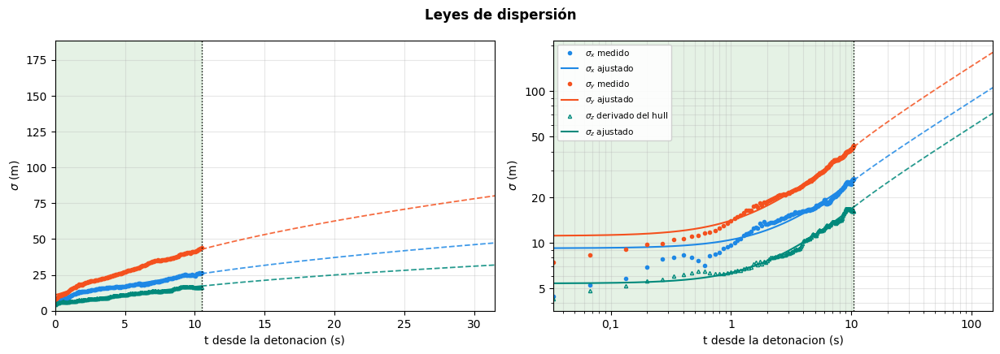

sigma_x: sigma^2 =   84.78 +   24.74 t^1.345   (R2 = 0.974, sigma(10.5 s) =  25.8 m, D_fin =   37.4 m2/s, superdifusivo)
sigma_y: sigma^2 =   123.4 +    73.5 t^1.340   (R2 = 0.996, sigma(10.5 s) =  42.8 m, D_fin =  109.5 m2/s, superdifusivo)
sigma_z: sigma^2 =   29.09 +    11.2 t^1.350   (R2 = 0.980, sigma(10.5 s) =  17.2 m, D_fin =   17.2 m2/s, superdifusivo)
razon sigma_z/sigma_y del hull: mediana 0.412, cae 0.577 -> 0.370 en la ventana


In [57]:
MOSTRAR.add("leyes")

_LEYES = [("x", "sig_along", PAR["ley_along"], "#1E88E5", "o"),
          ("y", "sig_cross", PAR["ley_cross"], "#F4511E", "o")]

if PAR["proyeccion"]["corregido"]:
    _res   = (PERFIL3D["resuelto"] if PERFIL3D["resuelto"].sum() >= 3
              else np.ones(PERFIL3D["n"], bool))
    _razon = np.interp(PAR["t"], PERFIL3D["t"][_res],
                       (PERFIL3D["s_z"] / np.maximum(PERFIL3D["s_cross"], 1e-6))[_res])
    _sz_obs = _razon * np.array([f["sig_cross"] for f in PAR["filas"]], float)
    _LEYES.append(("z", None, PAR["ley_z"], "#00897B", "^"))

_tf  = PAR["ley_along"]["t_fin"]
_t0  = max(PAR["t"].min(), 0.03)
_med = np.geomspace(_t0, _tf, 200)
_ext = np.geomspace(_tf, 150.0, 200)

fig, ax = plt.subplots(1, 2, figsize=(12.4, 4.4))
for _eje, _k, _ley, _col, _mk in _LEYES:
    _obs = _sz_obs if _k is None else [f[_k] for f in PAR["filas"]]
    for a in ax:
        a.plot(PAR["t"], _obs, _mk, ms=3.0, color=_col,
               mfc="none" if _k is None else _col,
               label=(f"$\\sigma_{_eje}$ derivado del hull" if _k is None
                      else f"$\\sigma_{_eje}$ medido"))
        a.plot(_med, _ley["sigma"](_med), "-", lw=1.5, color=_col,
               label=f"$\\sigma_{_eje}$ ajustado")
        a.plot(_ext, _ley["sigma"](_ext), "--", lw=1.3, color=_col, alpha=.85)

for a in ax:
    a.axvspan(_t0, _tf, color="green", alpha=.10)
    a.axvline(_tf, color="k", ls=":", lw=1)
    a.set_xlabel("t desde la detonacion (s)")
    a.set_ylabel(r"$\sigma$ (m)")
    a.grid(alpha=.3, which="both")

ax[0].set_xlim(0, 3.0 * _tf); ax[0].set_ylim(0, None)
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlim(_t0, 150.0); ax[1].set_xticks([0.1, 1.0, 10.0, 100.0])
ax[1].set_xticklabels(["0,1", "1", "10", "100"])
ax[1].set_yticks([5, 10, 20, 50, 100])
ax[1].set_yticklabels(["5", "10", "20", "50", "100"])
ax[1].legend(fontsize=7.5, loc="upper left", ncol=1, framealpha=.9)

fig.suptitle("Leyes de dispersión", fontweight="bold")
plt.tight_layout()
_png = CFG.ruta(4, "leyes_sigma.png")
fig.savefig(_png, dpi=140, bbox_inches="tight")
print(f"[fig] {F0.ruta_corta(_png)}")
mostrar(fig, "leyes")

for _eje, _k, _ley, _, _ in _LEYES:
    print(f"sigma_{_eje}: sigma^2 = {_ley['sigma0_m']**2:7.4g} + "
          f"{_ley['K']:7.4g} t^{_ley['alpha']:.3f}   "
          f"(R2 = {_ley['r2']:.3f}, sigma({_tf:.1f} s) = {_ley['sigma_fin']:5.1f} m, "
          f"D_fin = {_ley['D_fin_m2s']:6.1f} m2/s, {_ley['regimen']})")
if PAR["proyeccion"]["corregido"]:
    print(f"razon sigma_z/sigma_y del hull: mediana {np.median(_razon):.3f}, "
          f"cae {_razon[0]:.3f} -> {_razon[-1]:.3f} en la ventana")

## F4-4 — Evaluación de $\chi$

Con $u$, $H$ y las tres leyes $\sigma_i(t)$ la expresión del paso 2 queda
determinada. Se evalúa en tres cortes:

- $\chi(t)$ en el centro del puff, $x=ut$, $y=0$, para $z=H$.

$\sigma_i(t)$ está medido hasta $t_{fin}$; más allá la ley se continúa con
$d\sigma_i^2/dt$ constante, es decir con $\alpha_i=1$. En las figuras se distingue
el tramo medido del extrapolado.

[fig] resultados\4_pmx\chi.png


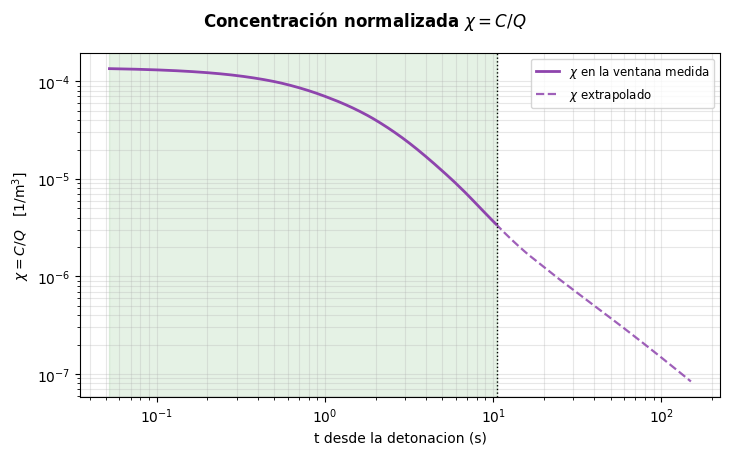

chi(z=H) : 0.000135 -> 3.39e-06 1/m3 en la ventana medida (0.05 - 10.48 s)
chi(150 s) = 8.39e-08 1/m3   [extrapolado]


In [58]:
MOSTRAR.add("chi")

_SER = F4.serie_chi(PAR)
_t   = _SER["t"]
_chi = _SER["chi_nube"]
_tf  = _SER["t_fin_medido"]
_i   = int(np.searchsorted(_t, _tf, side="right"))

fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.plot(_t[:_i], _chi[:_i], "-", lw=2.0, color="#8E44AD",
        label=r"$\chi$ en la ventana medida")
ax.plot(_t[max(_i - 1, 0):], _chi[max(_i - 1, 0):], "--", lw=1.6,
        color="#8E44AD", alpha=.85, label=r"$\chi$ extrapolado")
ax.axvspan(_t[0], _tf, color="green", alpha=.10)
ax.axvline(_tf, color="k", ls=":", lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("t desde la detonacion (s)")
ax.set_ylabel(r"$\chi = C/Q$   [1/m$^3$]")
ax.grid(alpha=.3, which="both")
ax.legend(fontsize=8.5)

fig.suptitle(r"Concentración normalizada $\chi = C/Q$", fontweight="bold")
plt.tight_layout()
_png = CFG.ruta(4, "chi.png")
fig.savefig(_png, dpi=140, bbox_inches="tight")
print(f"[fig] {F0.ruta_corta(_png)}")
mostrar(fig, "chi")

print(f"chi(z=H) : {np.interp(_t[0], _t, _chi):.3g} -> "
      f"{np.interp(_tf, _t, _chi):.3g} 1/m3 en la ventana medida "
      f"({_t[0]:.2f} - {_tf:.2f} s)")
print(f"chi(150 s) = {_chi[-1]:.3g} 1/m3   [extrapolado]")

## F4-5 — Ejemplos de concentraciones


[fig] resultados\4_pmx\magnitud.png


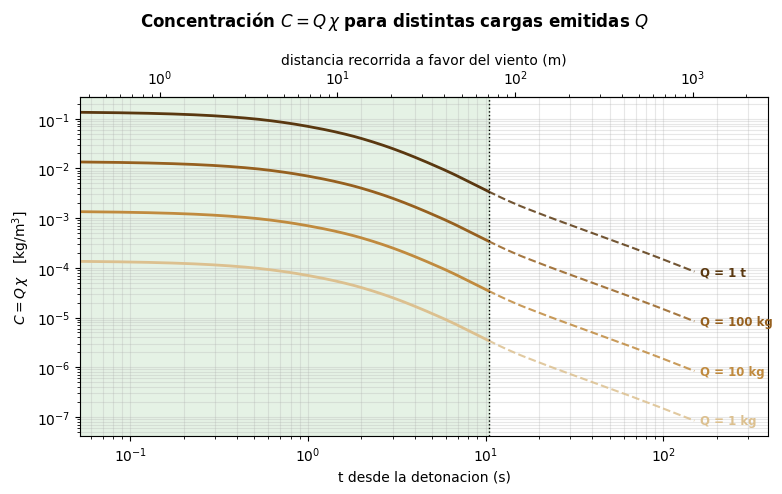

t =     5 s  (    34 m)  Q=    1 kg:   1.2e-05  Q=   10 kg:   0.00012  Q=  100 kg:    0.0012  Q= 1000 kg:     0.012  kg/m3
t =    20 s  (   136 m)  Q=    1 kg:  1.25e-06  Q=   10 kg:  1.25e-05  Q=  100 kg:  0.000125  Q= 1000 kg:   0.00125  kg/m3   [extrapolado]
t =    60 s  (   409 m)  Q=    1 kg:  2.95e-07  Q=   10 kg:  2.95e-06  Q=  100 kg:  2.95e-05  Q= 1000 kg:  0.000295  kg/m3   [extrapolado]
t =   150 s  (  1023 m)  Q=    1 kg:  8.39e-08  Q=   10 kg:  8.39e-07  Q=  100 kg:  8.39e-06  Q= 1000 kg:  8.39e-05  kg/m3   [extrapolado]


In [59]:
MOSTRAR.add("magnitud")

Q_HIPOTESIS = [1, 10, 100, 1000]
_RAMPA = ("#DCC08F", "#C08A3E", "#96601F", "#5A3810")

_SER = F4.serie_chi(PAR)
_t   = _SER["t"]
_tf  = _SER["t_fin_medido"]
_u   = float(PAR["u_ms"])
_i   = int(np.searchsorted(_t, _tf, side="right"))
_c   = _SER["chi_nube"]

fig, ax = plt.subplots(figsize=(8.0, 5.0))
for _k, _q in enumerate(Q_HIPOTESIS):
    _col = _RAMPA[_k % len(_RAMPA)]
    _y   = _q * _c
    ax.plot(_t[:_i], _y[:_i], "-", lw=2.0, color=_col)
    ax.plot(_t[max(_i - 1, 0):], _y[max(_i - 1, 0):], "--", lw=1.5,
            color=_col, alpha=.85)
    ax.annotate(f"Q = {_q:g} kg" if _q < 1000 else "Q = 1 t",
                xy=(_t[-1], _y[-1]), xytext=(4, 0), textcoords="offset points",
                color=_col, fontsize=8.5, va="center", fontweight="bold")

ax.axvspan(_t[0], _tf, color="green", alpha=.10)
ax.axvline(_tf, color="k", ls=":", lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(_t[0], _t[-1] * 2.6)
ax.set_xlabel("t desde la detonacion (s)")
ax.set_ylabel(r"$C = Q\,\chi$   [kg/m$^3$]")
_sec = ax.secondary_xaxis("top", functions=(lambda x: x * _u, lambda d: d / _u))
_sec.set_xlabel("distancia recorrida a favor del viento (m)")
ax.grid(alpha=.3, which="both")

fig.suptitle(r"Concentración $C = Q\,\chi$ para distintas cargas emitidas $Q$",
             fontweight="bold")
plt.tight_layout()
_png = CFG.ruta(4, "magnitud.png")
fig.savefig(_png, dpi=140, bbox_inches="tight")
print(f"[fig] {F0.ruta_corta(_png)}")
mostrar(fig, "magnitud")

for _tt in (5.0, 20.0, 60.0, 150.0):
    _ch = float(np.interp(_tt, _t, _SER["chi_nube"]))
    print(f"t = {_tt:5.0f} s  ({_u*_tt:6.0f} m)  " +
          "  ".join(f"Q={_q:5g} kg: {_q*_ch:9.3g}" for _q in Q_HIPOTESIS) +
          "  kg/m3" + ("" if _tt <= _tf else "   [extrapolado]"))

In [60]:
_SER_R = F4.serie_chi(PAR)
_tf_R  = float(PAR["ley_along"]["t_fin"])

def _resumen_ley(l):
    return {k: l[k] for k in ("alpha", "K", "sigma0_m", "r2", "regimen", "modelo",
                              "modo", "t_min", "t_ini", "t_fin", "sigma_fin",
                              "D_fin_m2s", "n", "origen") if k in l}

_CONC = []
for _tt in (5.0, 20.0, 60.0, 150.0):
    _ch = float(np.interp(_tt, _SER_R["t"], _SER_R["chi_nube"]))
    _CONC.append(dict(t_s=_tt, distancia_m=float(PAR["u_ms"]) * _tt,
                      extrapolado=bool(_tt > _tf_R), chi_1_m3=_ch,
                      C_kg_m3={f"{_q} kg": _q * _ch for _q in Q_HIPOTESIS}))

META = dict(
    unidades="chi = C/Q en 1/m3; C = Q*chi con Q en kg da kg/m3",
    cota_evaluacion="z = H(t), centro de la nube",
    fuente_utm=[float(v) for v in PAR["fuente"]],
    altura_efectiva_m=float(PAR["H"]),
    altura_modelo=("H(t) = centroide del hull (Fase 2), interpolado por instante"
                   if callable(PAR.get("ley_H")) else "H CONSTANTE (sin Fase 2)"),
    viento_ms=float(PAR["u_ms"]), azimut_hacia_deg=float(PAR["azimut_hacia"]),
    ventana_frames=[int(PAR["ventana"][0]), int(PAR["ventana"][-1])],
    ventana_s=[float(PAR["ley_along"]["t_ini"]), _tf_R],
    sigma_along=_resumen_ley(PAR["ley_along"]),
    sigma_cross=_resumen_ley(PAR["ley_cross"]),
    sigma_z=_resumen_ley(PAR["ley_z"]),
    razon_vertical_hull=float(CHK3D["razon_vertical_hull"]),
    incertidumbre_razon_pct=float(CHK3D["incertidumbre_razon_pct"]),
    momentos="pesados por opacidad" if PAR["pesado"] else "SILUETA binaria",
    proyeccion=PAR["proyeccion"], calidad_viento_fase3=PAR["calidad"],
    Q_hipotesis_kg=list(Q_HIPOTESIS), concentraciones=_CONC,
    no_modela=["deposicion/sedimentacion", "terreno (plano con reflexion)",
               "cizalle vertical del viento", "flotabilidad inicial",
               "el ascenso de la fuente en el balance (H(t) entra al evaluar, "
               "no en la ecuacion)"])

_ruta_meta = CFG.ruta(4, "parametros_dispersion.json")
with open(_ruta_meta, "w", encoding="utf-8") as fh:
    json.dump(META, fh, indent=2, ensure_ascii=False, default=F4.json_seguro)
print(f"[artefacto] {F0.ruta_corta(_ruta_meta)}")

F0.sellar(CFG, 4, dict(
    H_m=float(PAR["H"]),
    alpha_along=float(PAR["ley_along"]["alpha"]),
    alpha_cross=float(PAR["ley_cross"]["alpha"]),
    alpha_z=float(PAR["ley_z"]["alpha"]),
    sigma_z_fin_m=float(PAR["ley_z"]["sigma_fin"]),
    t_fin_medido_s=_tf_R,
    chi_t_fin_1_m3=float(np.interp(_tf_R, _SER_R["t"], _SER_R["chi_nube"])),
    pesado=bool(PAR["pesado"]),
    corregido_fase2=bool(PAR["proyeccion"]["corregido"])))
print("[sello] fase 4 anotada en procedencia.json")

[artefacto] resultados\4_pmx\parametros_dispersion.json
[sello] fase 4 anotada en procedencia.json
